# Dimensionality reduction techniques

In this notebook we will present some of the most important techniques of dimensionality analysis. We will show how to perform Principal component analysis (PCA), t-SNE, UMAP and autoencoders. The theoretical foundaing of this techniques can be found on the lecture notes. We will test these methods with already pre-build dataset of scikit.

In the last part of the notebook we go further with the autoencoders. We will build an autoencoder whose encoder starts with a **Convolutional Neural Network (CNN)**, train it monitoring the training and validation losses, compute which **regions** of each digit the encoder looks at, turn it into a **Variational Autoencoder (VAE)**, compare all the techniques, and finally use the trained model on **digits drawn by you**.

### Import all the neccesary packages

If you get an error saying that some package does not exist you can install it running: !pip install "package_name" in one cell.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_iris, load_wine, load_digits
from umap import UMAP
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
import seaborn as sns
import pandas as pd
from tqdm import tqdm

Packages and settings for the autoencoder part of the notebook:

In [2]:
import copy
import os
from sklearn.neighbors import KNeighborsClassifier
from tqdm.autonotebook import trange
import warnings
warnings.filterwarnings('ignore')

torch.manual_seed(0)
np.random.seed(0)

## Plot the three data bases that we are going to use

We are going to use three data bases: iris, wine and digits. In here we present the details of each of them.

### Iris

This data base contains infromation about 3 different type of flowers, classified as 0, 1 and 2 by the target flag. In the following cell of code we will load the data, show its feautures and plot them. We can see that each of the flower has four features:
- Sepal length
- Sepald width
- Petal length
- Petal width

Thus, in the notation that we have presented in class, the data matrix will be in $\mathbb{R}^{150,4}$, with $150$ being the number of measures and $4$ the number of features


DataFrame Info:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


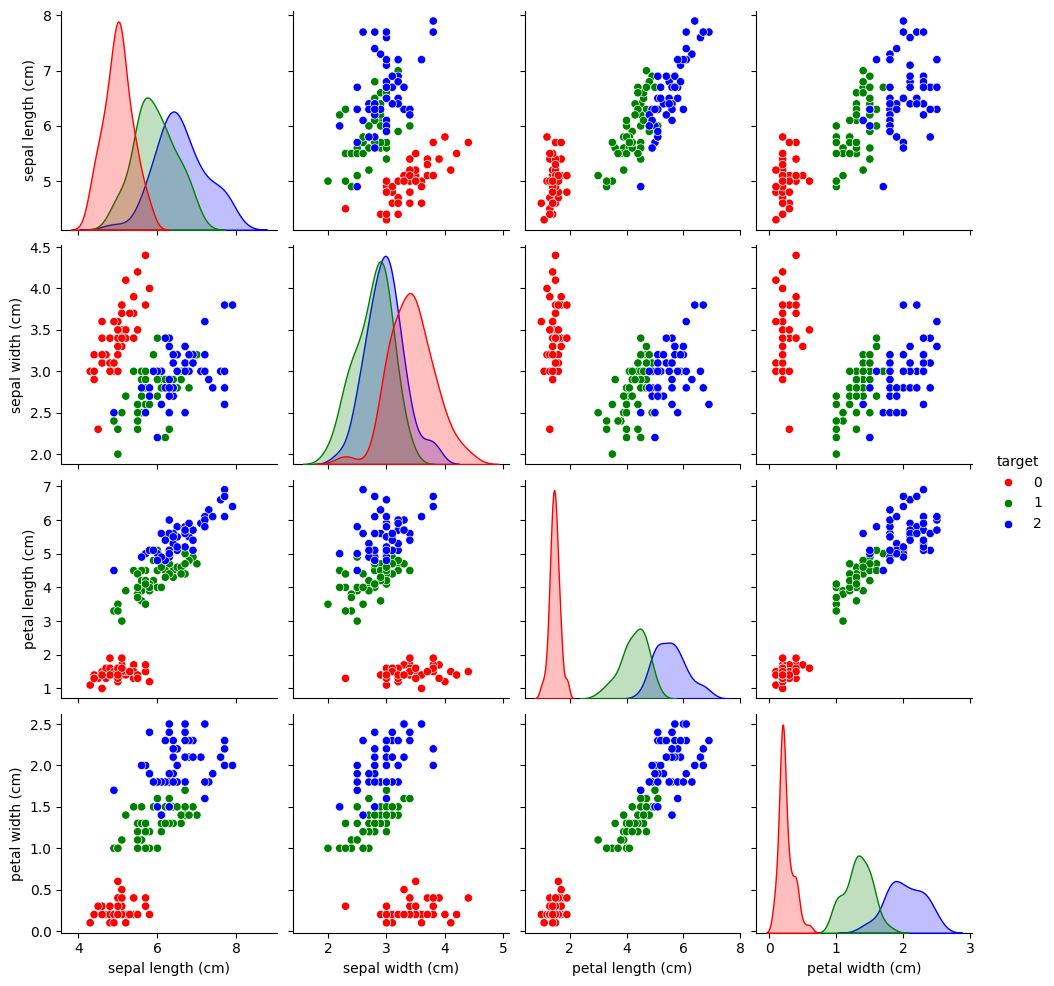

In [3]:
# Load iris dataset and print all the important infromation #
data = load_iris()
X = data.data
y = data.target

# Display comprehensive dataframe info
print("\nDataFrame Info:")
df_iris = pd.DataFrame(X, columns=data.feature_names)
df_iris['target'] = y
display(df_iris.describe())

# Do an snset pairplot to visualize the data #
df = pd.DataFrame(X, columns=data.feature_names)
df['target'] = y
# use 'palette' instead of the unsupported 'colors' argument
sns.pairplot(df, hue='target', palette=['red', 'green', 'blue'])

### Wine dataset

We will now load the wine dataset. This data set contains 13 properties of 178 different wines. These are clasified into three different kinds. This dataset will be similar to the previous one, but it contains more features. Then, the data matrix will be $X \in \mathbb{R}^{178,13}$.

(178, 13)

DataFrame Info:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


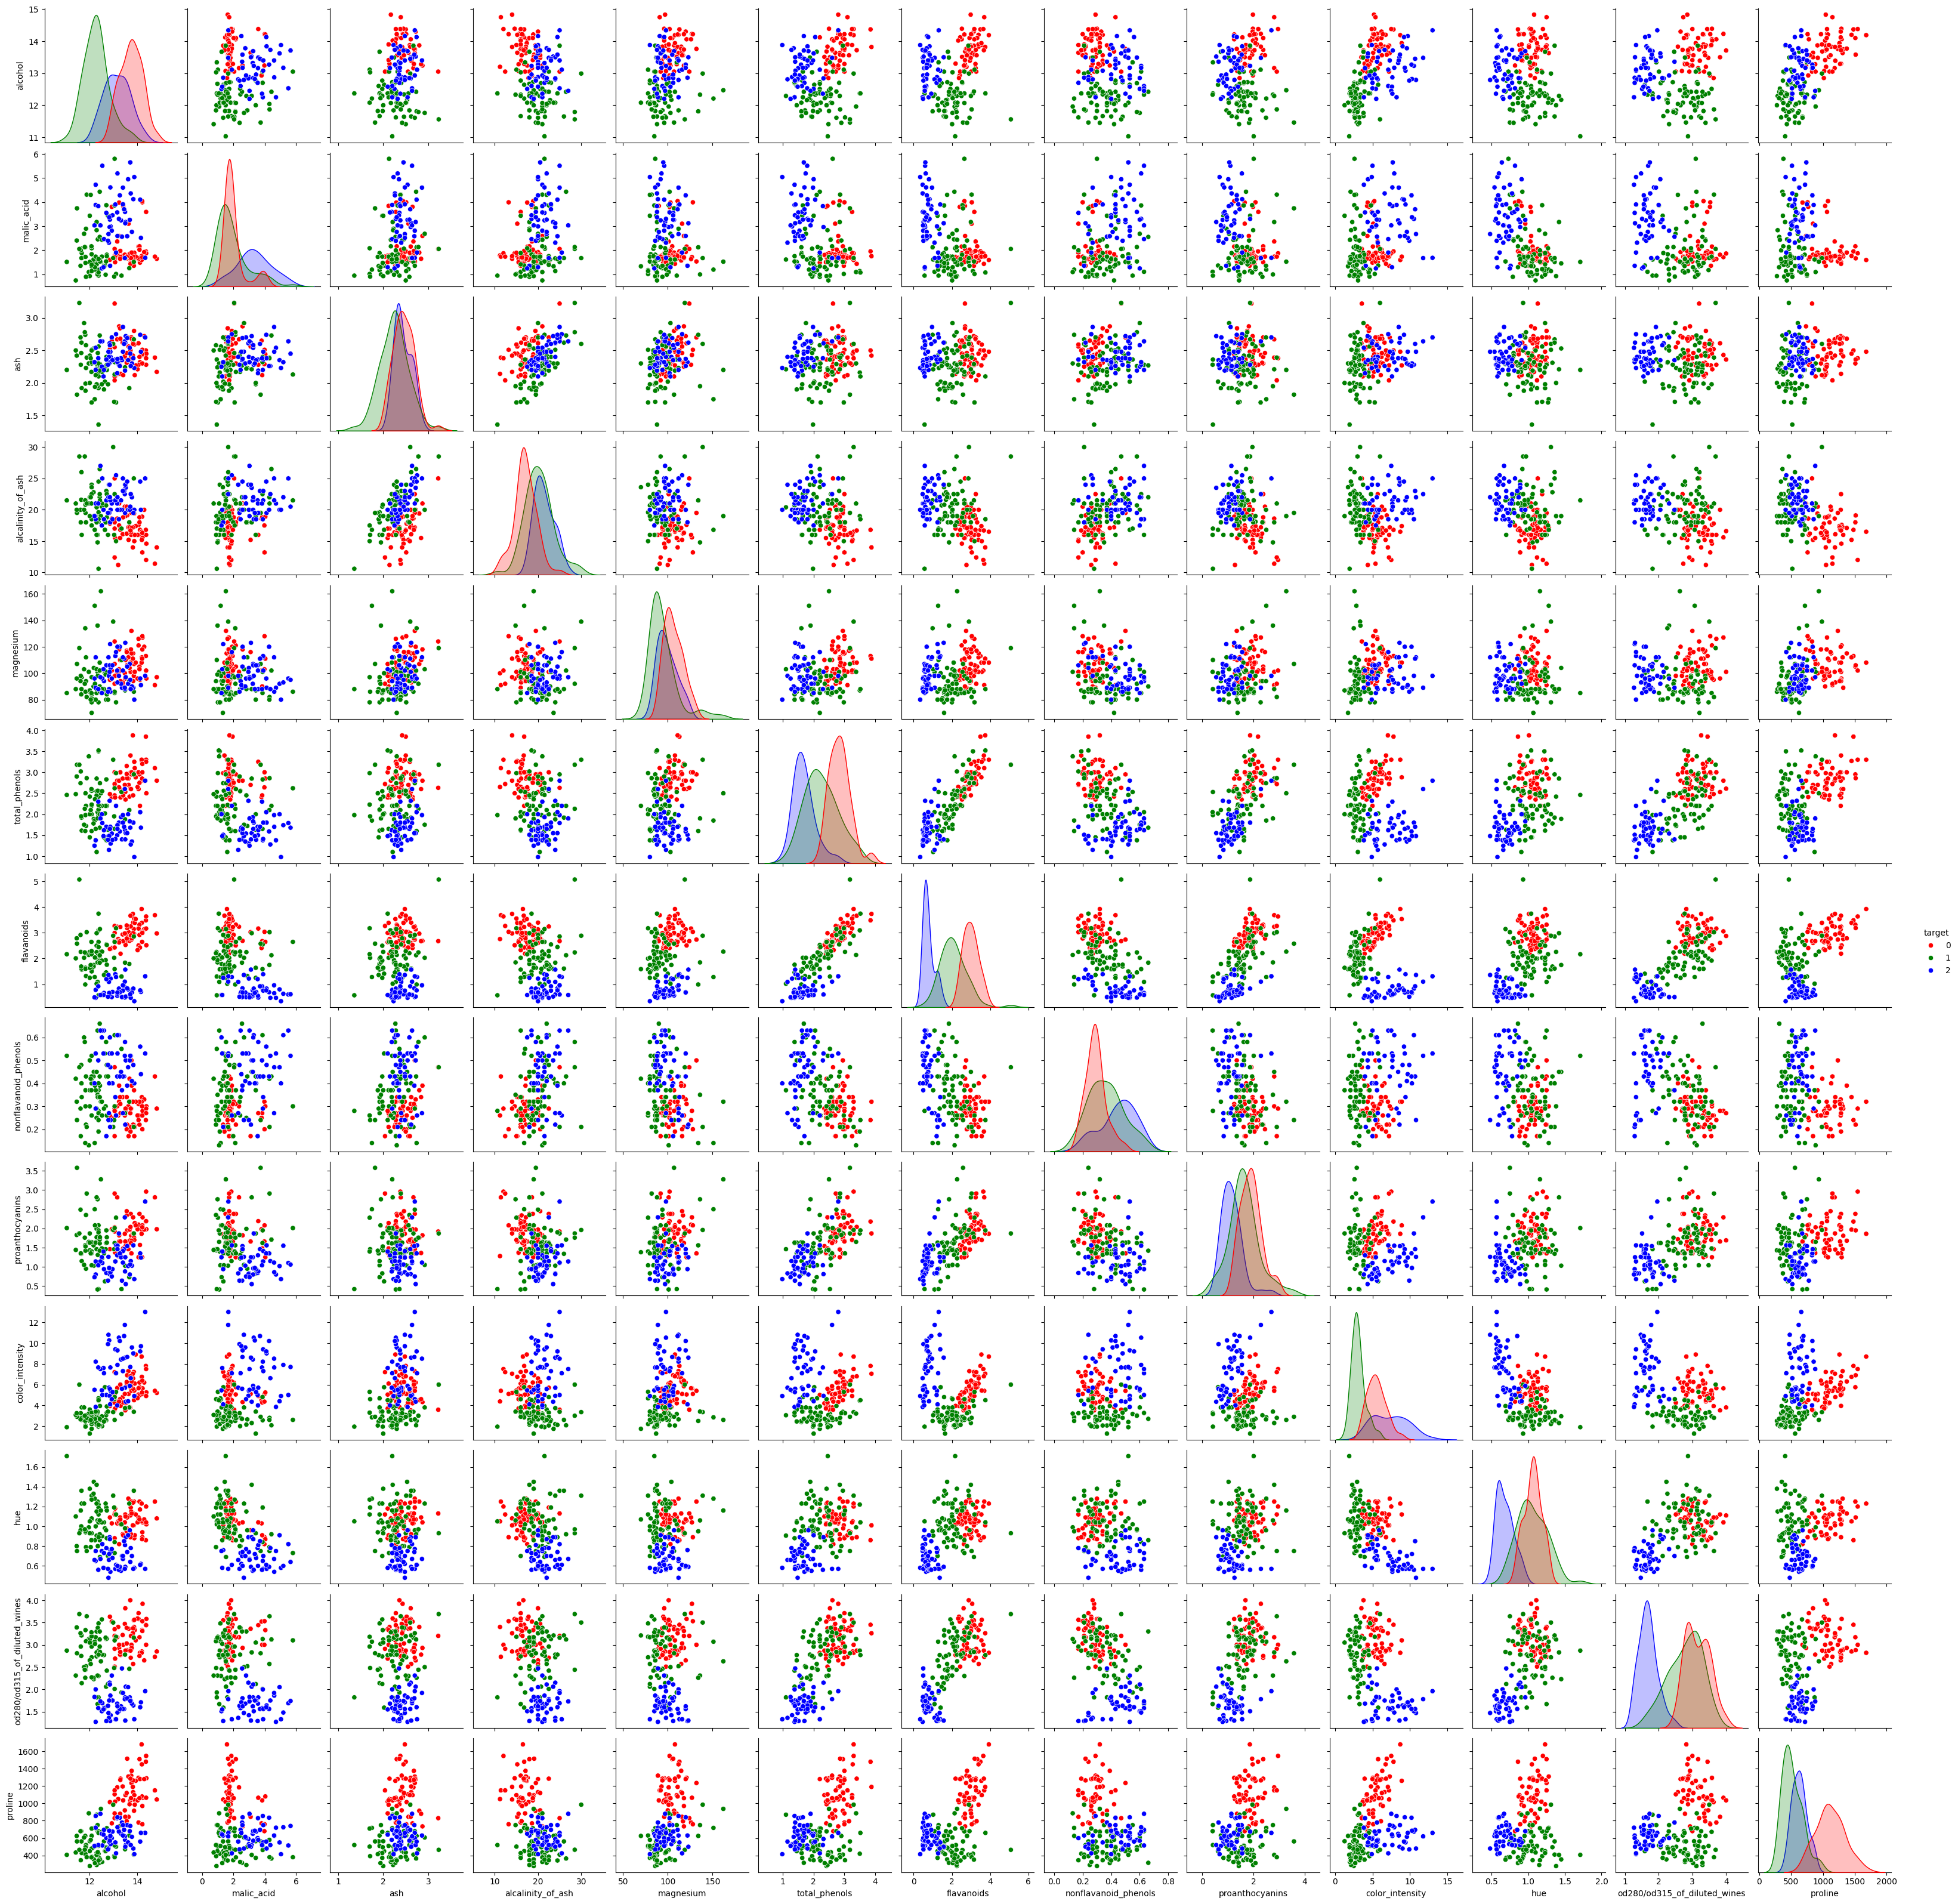

In [4]:
# Load wine dataset and print all the important infromation #
data = load_wine()
X = data.data
print(X.shape)
y = data.target

# Display comprehensive dataframe info
print("\nDataFrame Info:")
df_wine = pd.DataFrame(X, columns=data.feature_names)
df_wine['target'] = y
display(df_wine.describe())

# Do an snset pairplot to visualize the data #
df = pd.DataFrame(X, columns=data.feature_names)
df['target'] = y
# use 'palette' instead of the unsupported 'colors' argument
sns.pairplot(df, hue='target', palette=['red', 'green', 'blue'])

### Digits data set

We will present here the digits dataset. These correspond to 1797 handwritten digits between 0 and 9. These are written on a grid of 8x8. Then, the data will show the intensity of each pixel (on a scale from 0 to 16). In our language, we have 1797 number of samples with $64$ feature each. Then, the data matrix will be $X\in \mathbb{R}^{1797,64}$

(1797, 64)

DataFrame Info:


,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7,pixel_1_0,pixel_1_1,...,pixel_6_7,pixel_7_0,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7,target
count,1797.0,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,...,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000
mean,0.0,0.303840,5.204786,11.835838,11.848080,5.781859,1.362270,0.129661,0.005565,1.993879,...,0.206455,0.000556,0.279354,5.557596,12.089037,11.809126,6.764051,2.067891,0.364496,4.490818
std,0.0,0.907192,4.754826,4.248842,4.287388,5.666418,3.325775,1.037383,0.094222,3.196160,...,0.984401,0.023590,0.934302,5.103019,4.374694,4.933947,5.900623,4.090548,1.860122,2.865304
min,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.0,0.000000,1.000000,10.000000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,1.000000,11.000000,10.000000,0.000000,0.000000,0.000000,2.000000
50%,0.0,0.000000,4.000000,13.000000,13.000000,4.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,4.000000,13.000000,14.000000,6.000000,0.000000,0.000000,4.000000
75%,0.0,0.000000,9.000000,15.000000,15.000000,11.000000,0.000000,0.000000,0.000000,3.000000,...,0.000000,0.000000,0.000000,10.000000,16.000000,16.000000,12.000000,2.000000,0.000000,7.000000
max,0.0,8.000000,16.000000,16.000000,16.000000,16.000000,16.000000,15.000000,2.000000,16.000000,...,13.000000,1.000000,9.000000,16.000000,16.000000,16.000000,16.000000,16.000000,16.000000,9.000000


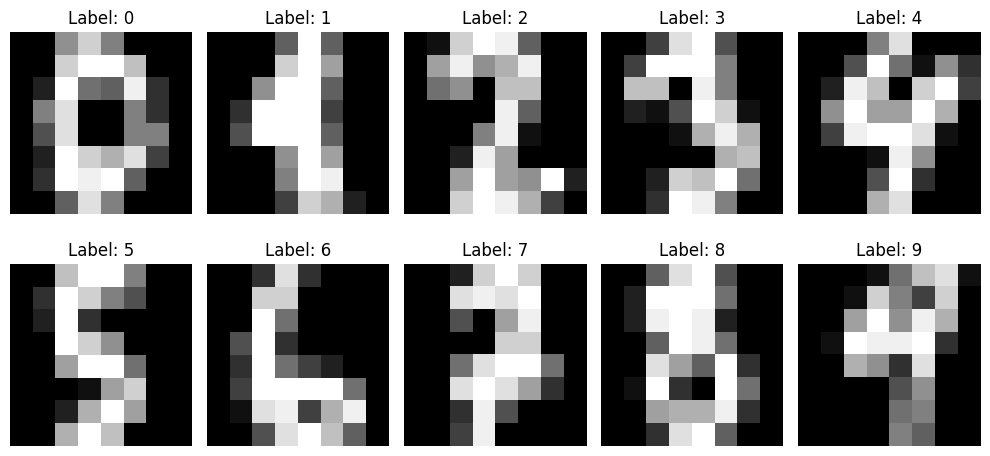

In [5]:
# Load digits dataset and print all the important infromation #
data = load_digits()
X = data.data
print(X.shape)
y = data.target

# Display comprehensive dataframe info
print("\nDataFrame Info:")
df_wine = pd.DataFrame(X, columns=data.feature_names)
df_wine['target'] = y
display(df_wine.describe())

# Do an imshow of some digits to visualize the data #
# Show one random image for each digit (0-9)
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for digit, ax in enumerate(axes.flat):
    indices = np.where(y == digit)[0]
    idx = np.random.choice(indices)
    ax.imshow(X[idx].reshape(8, 8), cmap='gray')
    ax.set_title(f"Label: {digit}")
    ax.axis('off')
plt.tight_layout()
plt.show()

## Principal component analysis

### Example

We first present a Principal Component Analysis on a dataset. In particular, we will test this method with the first dataset since it is the simplest one. As it is explained on the lectures notes, PCA will find the directions along which the eigenvalues of the covariance matrix of data are the largest. We will identify this components as the principal directions.

Since we will use the iris dataset, we will perform a dimensionality reducition from $4$ to $2$ features. The first setp of the dimensionality reduction will be to load the dataset and standardize it, this is, rescale and shift the data such that each feature has mean $0$ and standard deviation $1$. This can be done by the already built-in function $\texttt{StandardScaler}$.

In [6]:
# Load dataset
data = load_iris()
X = data.data
y = data.target

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

We now perform the PCA of the data. For this purpose we will use the function $\texttt{PCA}$, which input is going to be the data matrix. We then plot the transformed data along the two most dominant components. We do this plot in a 2,2 grid, using as color coding the value of the features. We can see here that we can approx. identify PCA1 with petal length, and PCA2 with sepal widht (but this is not as clear as the first one). 

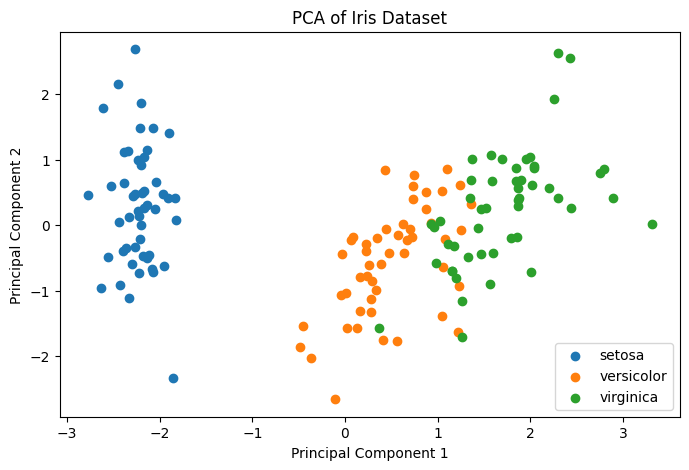

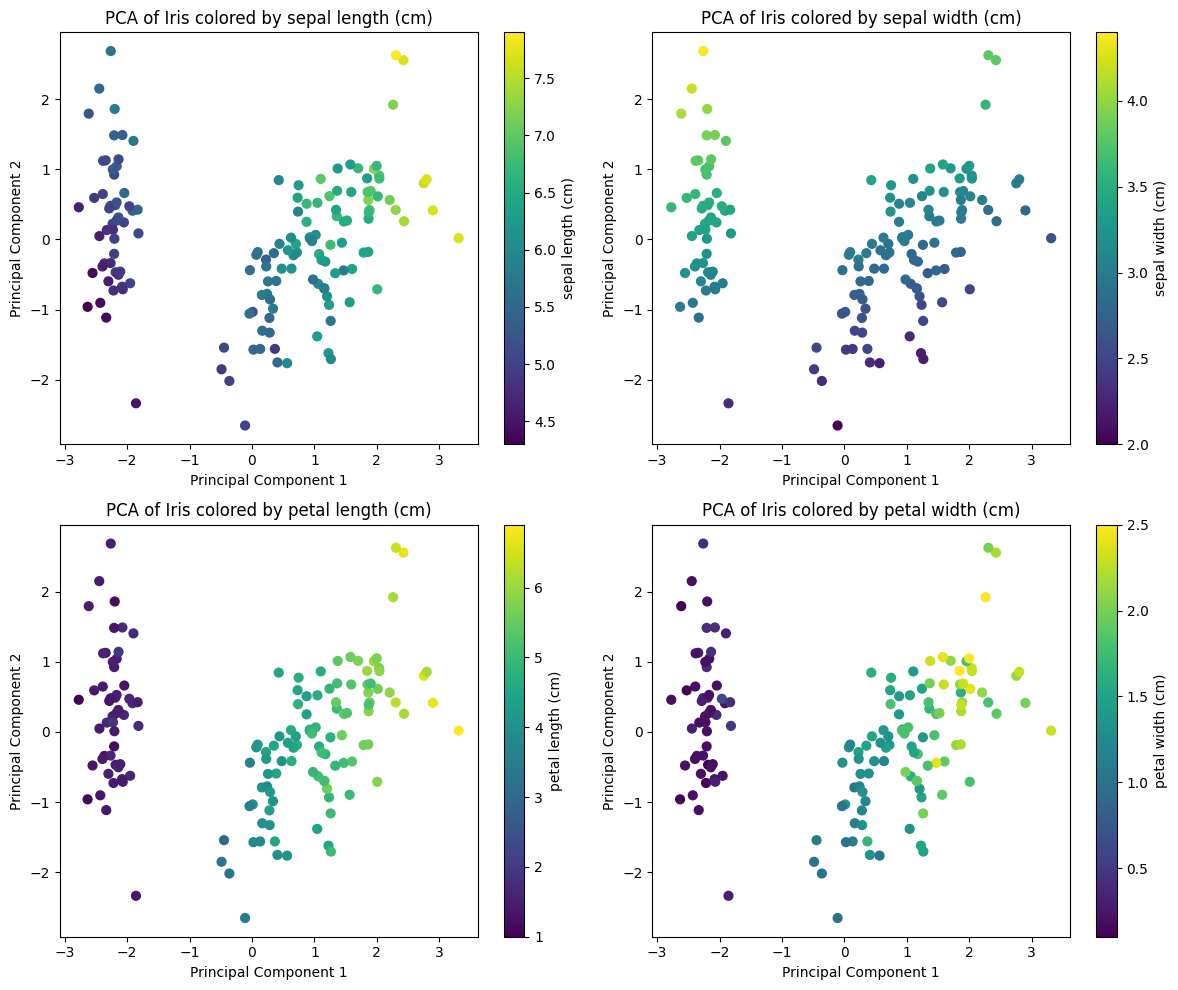

In [7]:
# Apply PCA (2 components) for the scatter plot
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Plot the reduced data
plt.figure(figsize=(8, 5))
for i, target_name in enumerate(data.target_names):
    plt.scatter(X_pca[y == i, 0], X_pca[y == i, 1], label=target_name)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA of Iris Dataset')
plt.legend()
plt.show()

# 2x2 scatter plots of PCA components colored by each iris feature
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
features = data.feature_names  # sepal length, sepal width, petal length, petal width

for ax, i in zip(axes.flat, range(X.shape[1])):
    sc = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=X[:, i], cmap='viridis', s=40)
    ax.set_title(f'PCA of Iris colored by {features[i]}')
    ax.set_xlabel('Principal Component 1')
    ax.set_ylabel('Principal Component 2')
    cbar = plt.colorbar(sc, ax=ax)
    cbar.set_label(features[i])

plt.tight_layout()
plt.show()


At last we show the value of the eigenvalues of the covariance matrix. We can see that we can explain up to $90\%$ of the original data using just two components of the PCA. These two components seem to be a mixture between petal information (for the first one) and sepal information (for the second)

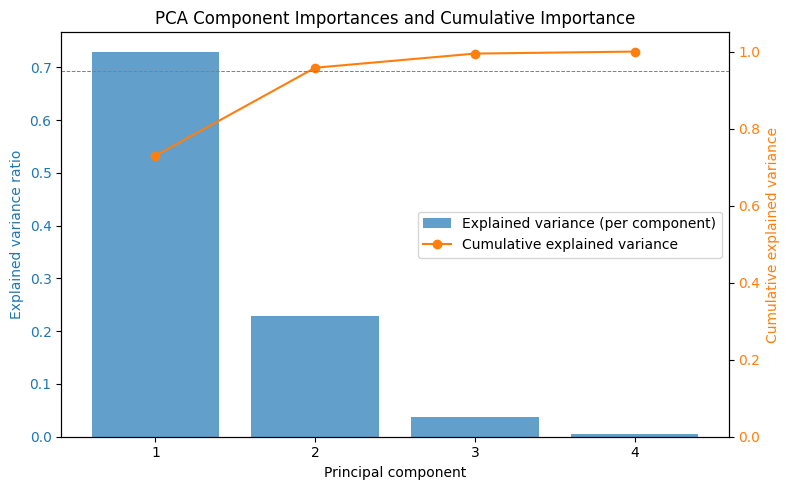

In [8]:
# Fit PCA with all components to get explained variance ratios
pca_full = PCA().fit(X_scaled)
ratios = pca_full.explained_variance_ratio_
cum_ratios = np.cumsum(ratios)
components = np.arange(1, len(ratios) + 1)

# Plot histogram (bar) of individual explained variance and cumulative importance (line)
fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.bar(components, ratios, alpha=0.7, color='C0', label='Explained variance (per component)')
ax1.set_xlabel('Principal component')
ax1.set_ylabel('Explained variance ratio', color='C0')
ax1.set_xticks(components)
ax1.tick_params(axis='y', labelcolor='C0')

ax2 = ax1.twinx()
ax2.plot(components, cum_ratios, color='C1', marker='o', label='Cumulative explained variance')
ax2.set_ylabel('Cumulative explained variance', color='C1')
ax2.set_ylim(0, 1.05)
ax2.tick_params(axis='y', labelcolor='C1')

# optional guideline and combined legend
ax2.axhline(0.95, color='gray', linestyle='--', linewidth=0.7)
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines + lines2, labels + labels2,loc='center right')

plt.title('PCA Component Importances and Cumulative Importance')
plt.tight_layout()
plt.show()

### Try it yourself!

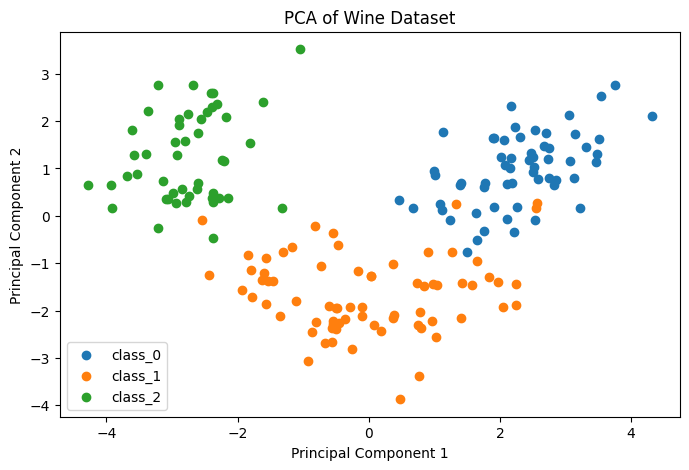

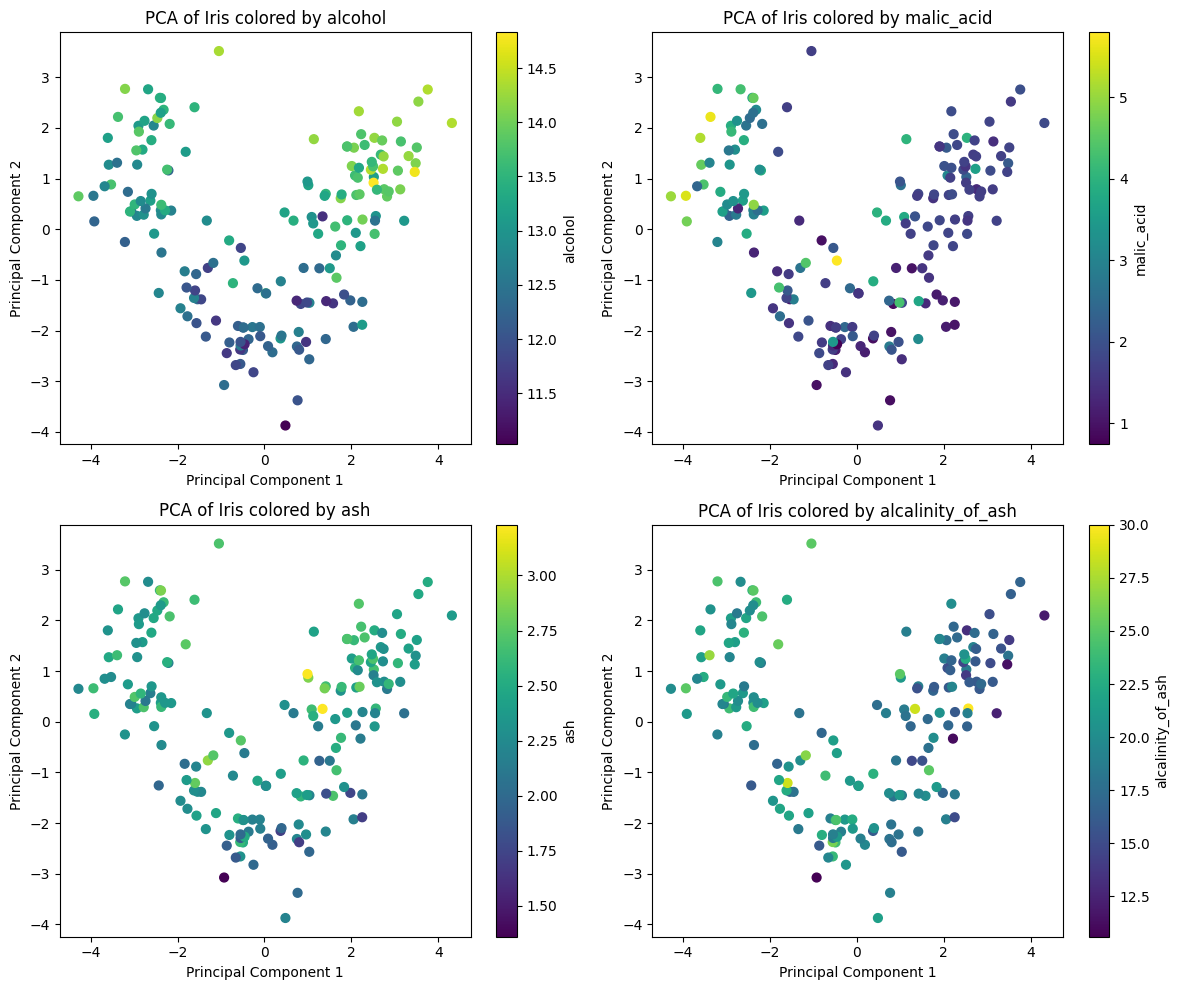

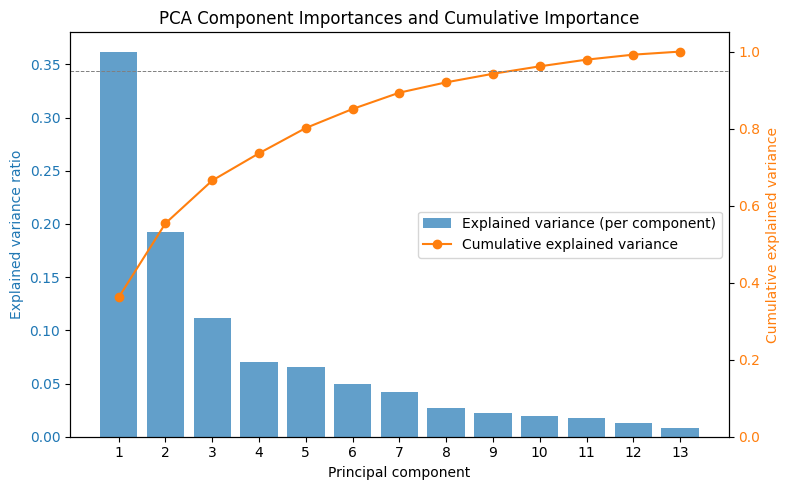

In [9]:
# Perform the same PCA analysis using another dataset #
# You can use wine, digits or whatever you like #
# Compare your results with the ones obtained for the iris dataset #
# Load dataset
data = load_wine()
X = data.data
y = data.target

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA (2 components) for the scatter plot
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Plot the reduced data
plt.figure(figsize=(8, 5))
for i, target_name in enumerate(data.target_names):
    plt.scatter(X_pca[y == i, 0], X_pca[y == i, 1], label=target_name)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA of Wine Dataset')
plt.legend()
plt.show()

# 2x2 scatter plots of PCA components colored by each wine feature
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
features = data.feature_names  # sepal length, sepal width, petal length, petal width

for ax, i in zip(axes.flat, range(X.shape[1])):
    sc = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=X[:, i], cmap='viridis', s=40)
    ax.set_title(f'PCA of Iris colored by {features[i]}')
    ax.set_xlabel('Principal Component 1')
    ax.set_ylabel('Principal Component 2')
    cbar = plt.colorbar(sc, ax=ax)
    cbar.set_label(features[i])

plt.tight_layout()
plt.show()

# Fit PCA with all components to get explained variance ratios
pca_full = PCA().fit(X_scaled)
ratios = pca_full.explained_variance_ratio_
cum_ratios = np.cumsum(ratios)
components = np.arange(1, len(ratios) + 1)

# Plot histogram (bar) of individual explained variance and cumulative importance (line)
fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.bar(components, ratios, alpha=0.7, color='C0', label='Explained variance (per component)')
ax1.set_xlabel('Principal component')
ax1.set_ylabel('Explained variance ratio', color='C0')
ax1.set_xticks(components)
ax1.tick_params(axis='y', labelcolor='C0')

ax2 = ax1.twinx()
ax2.plot(components, cum_ratios, color='C1', marker='o', label='Cumulative explained variance')
ax2.set_ylabel('Cumulative explained variance', color='C1')
ax2.set_ylim(0, 1.05)
ax2.tick_params(axis='y', labelcolor='C1')

# optional guideline and combined legend
ax2.axhline(0.95, color='gray', linestyle='--', linewidth=0.7)
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines + lines2, labels + labels2,loc='center right')

plt.title('PCA Component Importances and Cumulative Importance')
plt.tight_layout()
plt.show()


It seems that both for the wine and digits we need a lot of componentes to explain the data. One limitation of the PCA is that it is a linear dimensionality reduction technique. We will see how using other techniques like t-SNE and UMAP can better reduce our data

## t-SNE

### Example

We will now explain how to perform a dimensionality reduction using t-SNE. We will also compare the results with the ones obtained for the PCA. As we have written in the lecture notes, t-SNE is a non-linear dimensionality reduction techinque. This technique is built such that it will preserve the local structure of the data. This means that points that are closer in the $d$ dimensional data space, will remain closer in the reduced $m$ dimensional space.

We will test out this technique with the wine data base. This data set contains 13 properties of 178 different wines, that are classified into three types. The first step will be to load the data set and standarize it.

In [10]:
# Load dataset
data = load_wine()
X = data.data
print(X.shape)
y = data.target

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

(178, 13)


Then, we use the built-in function $\texttt{TSNE}$ to reduce the $13$ components to $2$. Note that TSNE will take an additional argument called the perplexity. The intuition behind this parameter is that the smaller it is, the closes each point will look for neighbors in the $d$ dimensional space. We will fix it to $25$.

We then plot the reduced components of the data. We can see that the local structure (similar wines are closer) is preserved. Since there are a lot features and t-SNE is a non-linear dimensionality reduction technique it is difficult to say which initial features will correspond to the reduced directions.

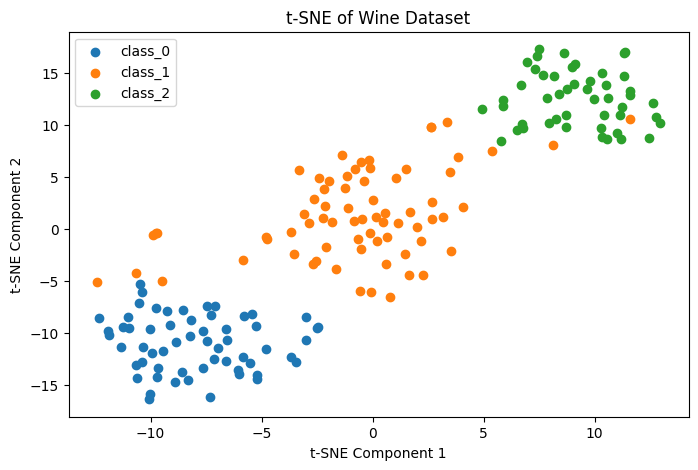

In [11]:

# Apply t-SNE for the scatter plot #
tsne = TSNE(n_components=2, perplexity=25)
X_tsne = tsne.fit_transform(X_scaled)

# Plot the reduced data
plt.figure(figsize=(8, 5))
for i, target_name in enumerate(data.target_names):
    plt.scatter(X_tsne[y == i, 0], X_tsne[y == i, 1], label=target_name)
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.title('t-SNE of Wine Dataset')
plt.legend()
plt.show()


### Try it yourself

Try applying tSNE to both iris and digits dataset. Comment the results. Compare tSNE with PCA in the case of iris dataset. Try changin the perplexity. What happens?

(1797, 64)


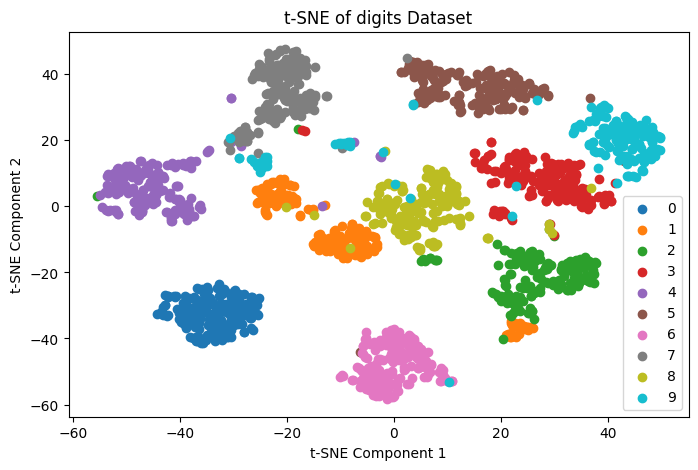

In [12]:
# Try using tsne for the digits dataset #
# Load dataset
data = load_digits()
X = data.data
print(X.shape)
y = data.target

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply t-SNE for the scatter plot #
tsne = TSNE(n_components=2, perplexity=25)
X_tsne = tsne.fit_transform(X_scaled)

# Plot the reduced data
plt.figure(figsize=(8, 5))
for i, target_name in enumerate(data.target_names):
    plt.scatter(X_tsne[y == i, 0], X_tsne[y == i, 1], label=target_name)
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.title('t-SNE of digits Dataset')
plt.legend()
plt.show()


(150, 4)


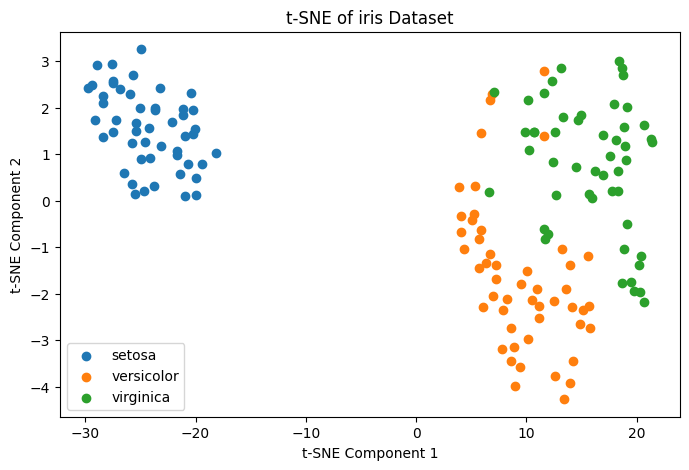

In [13]:
# Try using tsne for the digits dataset #
# Load dataset
data = load_iris()
X = data.data
print(X.shape)
y = data.target

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply t-SNE for the scatter plot #
tsne = TSNE(n_components=2, perplexity=25)
X_tsne = tsne.fit_transform(X_scaled)

# Plot the reduced data
plt.figure(figsize=(8, 5))
for i, target_name in enumerate(data.target_names):
    plt.scatter(X_tsne[y == i, 0], X_tsne[y == i, 1], label=target_name)
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.title('t-SNE of iris Dataset')
plt.legend()
plt.show()


tSNE does a better job than PCA when separating different types of flowers in the iris case. This is because of the local structure presentavion of the data. In the case of the digits the clustering is fantastic. By changing the value of the perplexity we can see that these clustering changes.

## UMAP

### Example

UMAP is very similar to tSNE. The main difference is that tSNE will only care about local structure of data. However, UMAP will also try to preserve some global features. We will test out this technique usnig the digits data set. We first load the data

In [14]:
# Load dataset
data = load_digits()
X = data.data
print(X.shape)
y = data.target
# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

(1797, 64)


In this dataset we have $1797$ hand-written numbers. Each of them is represented as an image of $8\times 8$ pixels. Thus, we can interpret these pixels as different features of the data, being the number of features $64$. To apply UMAP and reduce the components from $64$ to $2$ we use the prebuilt function $\texttt{UMAP}$. This will take as inputs the number of components, the minimum distance between points in the embedding and the number of local neighbors. By increasing the minimum distance parameter we will generate a less clustered embedding of the data. On the other hand, by increasing the number of neighbors we will be focusing on more global structures of the manifold than on local ones. 

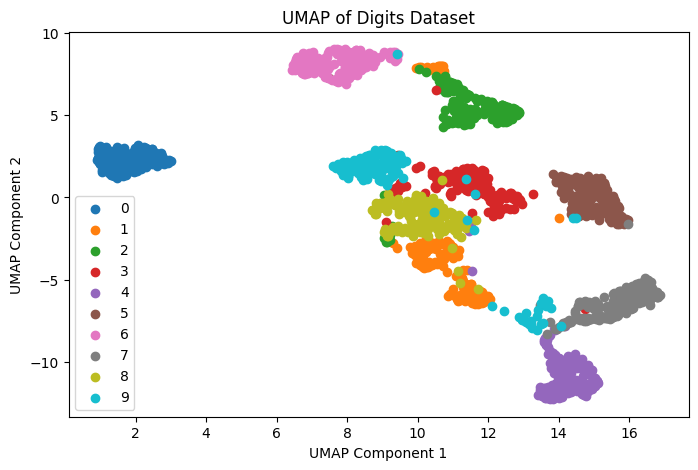

In [15]:

# Apply UMAP for the scatter plot #
reducer = UMAP(n_neighbors=15, min_dist=0.25, n_components=2)
X_umap = reducer.fit_transform(X_scaled)

# Plot the reduced data
plt.figure(figsize=(8, 5))
for i, target_name in enumerate(data.target_names):
    plt.scatter(X_umap[y == i, 0], X_umap[y == i, 1], label=target_name)
plt.xlabel('UMAP Component 1')
plt.ylabel('UMAP Component 2')
plt.title('UMAP of Digits Dataset')
plt.legend()
plt.show()


We cann see from here than the clustering is done extremely well, where there is very good agreement on the clusters with the internal tags that the data points have.

### Try it yourself!

(1797, 64)


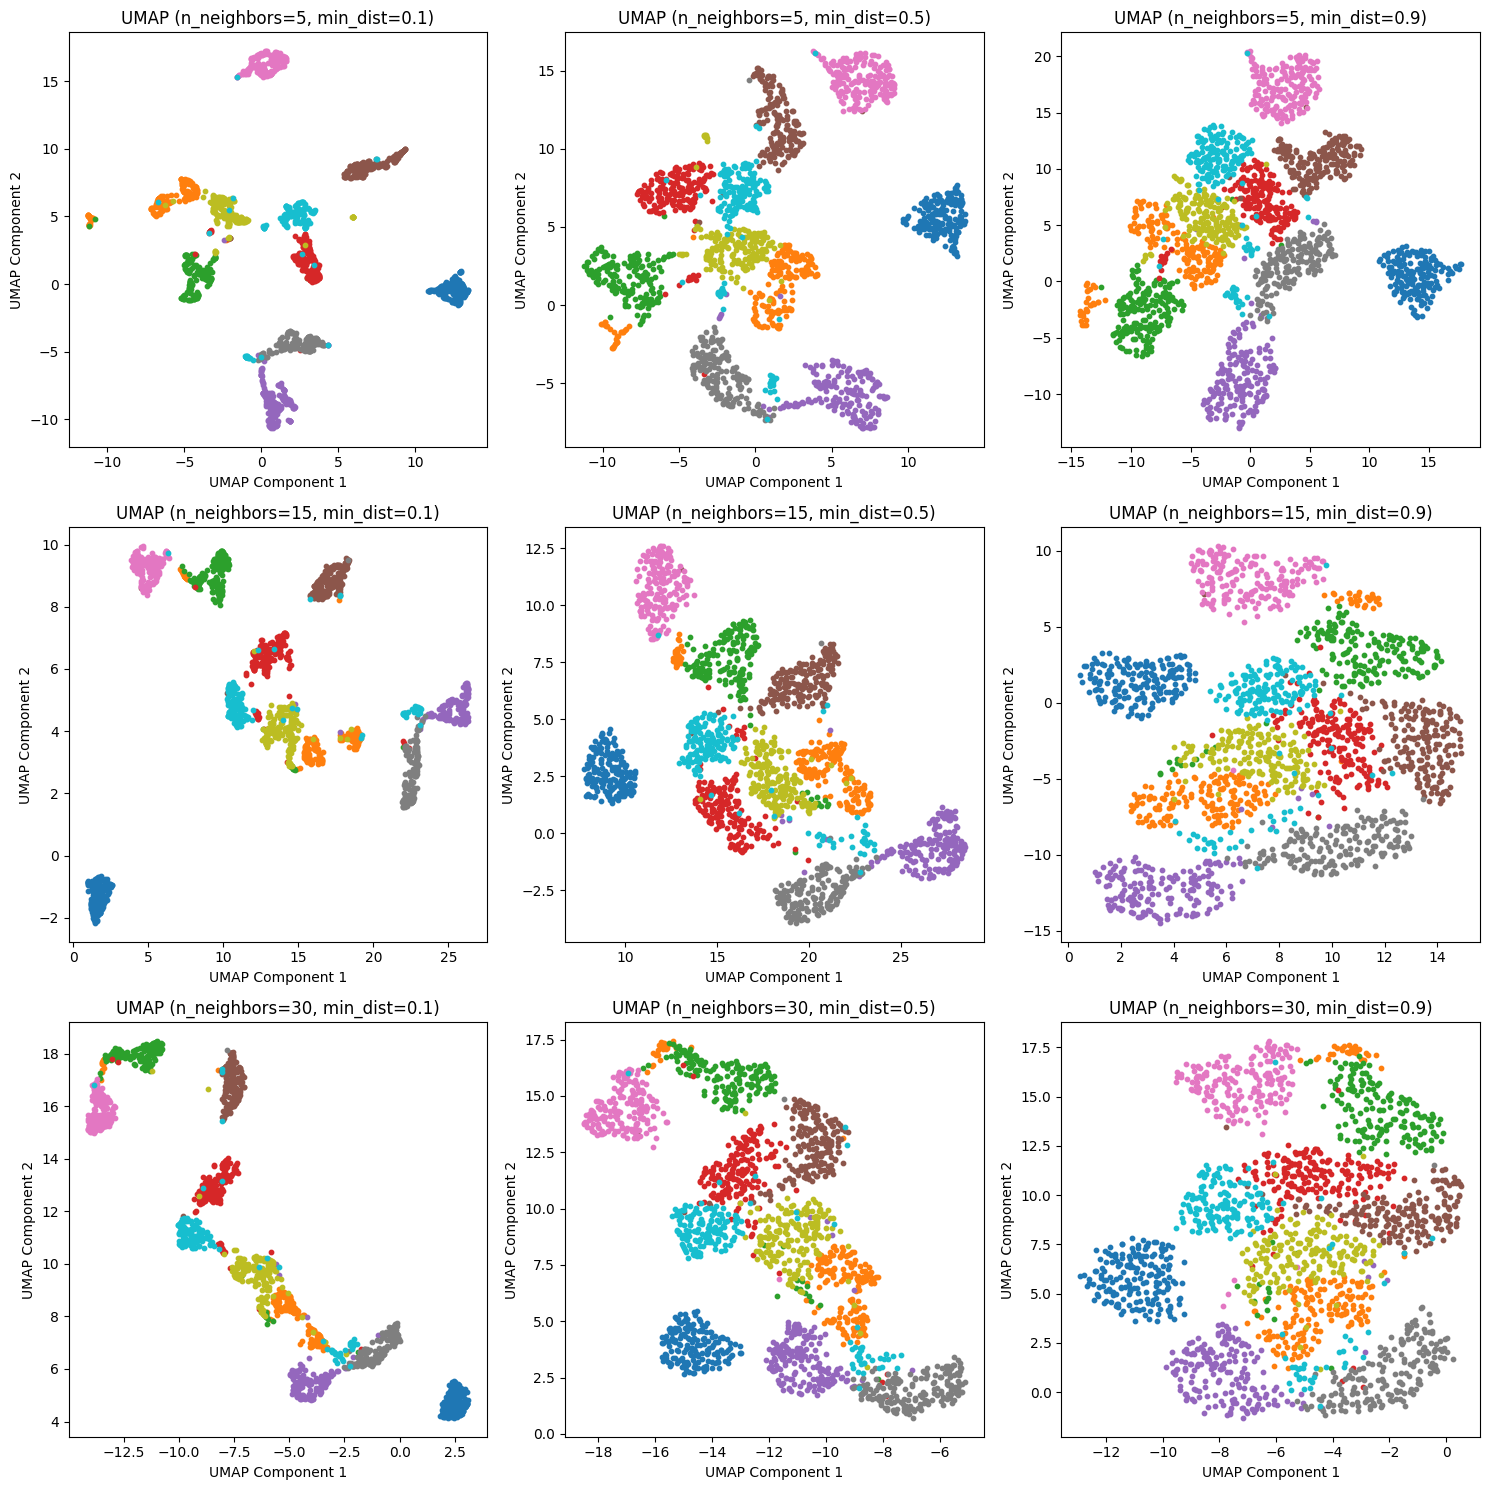

In [16]:
# Change the values of the number of neighbors and minimum distance to see how the embedding
# would change
# Load dataset
data = load_digits()
X = data.data
print(X.shape)
y = data.target
# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Different values for local neighbors and minimum distance #
n_neighbors = [5,15,30]
min_dist = [0.1,0.5,0.9]

# Do a grid of plots 3x3 with the different combinations
fig, axes = plt.subplots(3, 3, figsize=(15, 15))
for i, n in enumerate(n_neighbors):
    for j, d in enumerate(min_dist):
        reducer = UMAP(n_neighbors=n, min_dist=d, n_components=2)
        X_umap = reducer.fit_transform(X_scaled)
        ax = axes[i, j]
        for k, target_name in enumerate(data.target_names):
            ax.scatter(X_umap[y == k, 0], X_umap[y == k, 1], label=target_name, s=10)
        ax.set_title(f'UMAP (n_neighbors={n}, min_dist={d})')
        ax.set_xlabel('UMAP Component 1')
        ax.set_ylabel('UMAP Component 2')

plt.tight_layout()
plt.show()

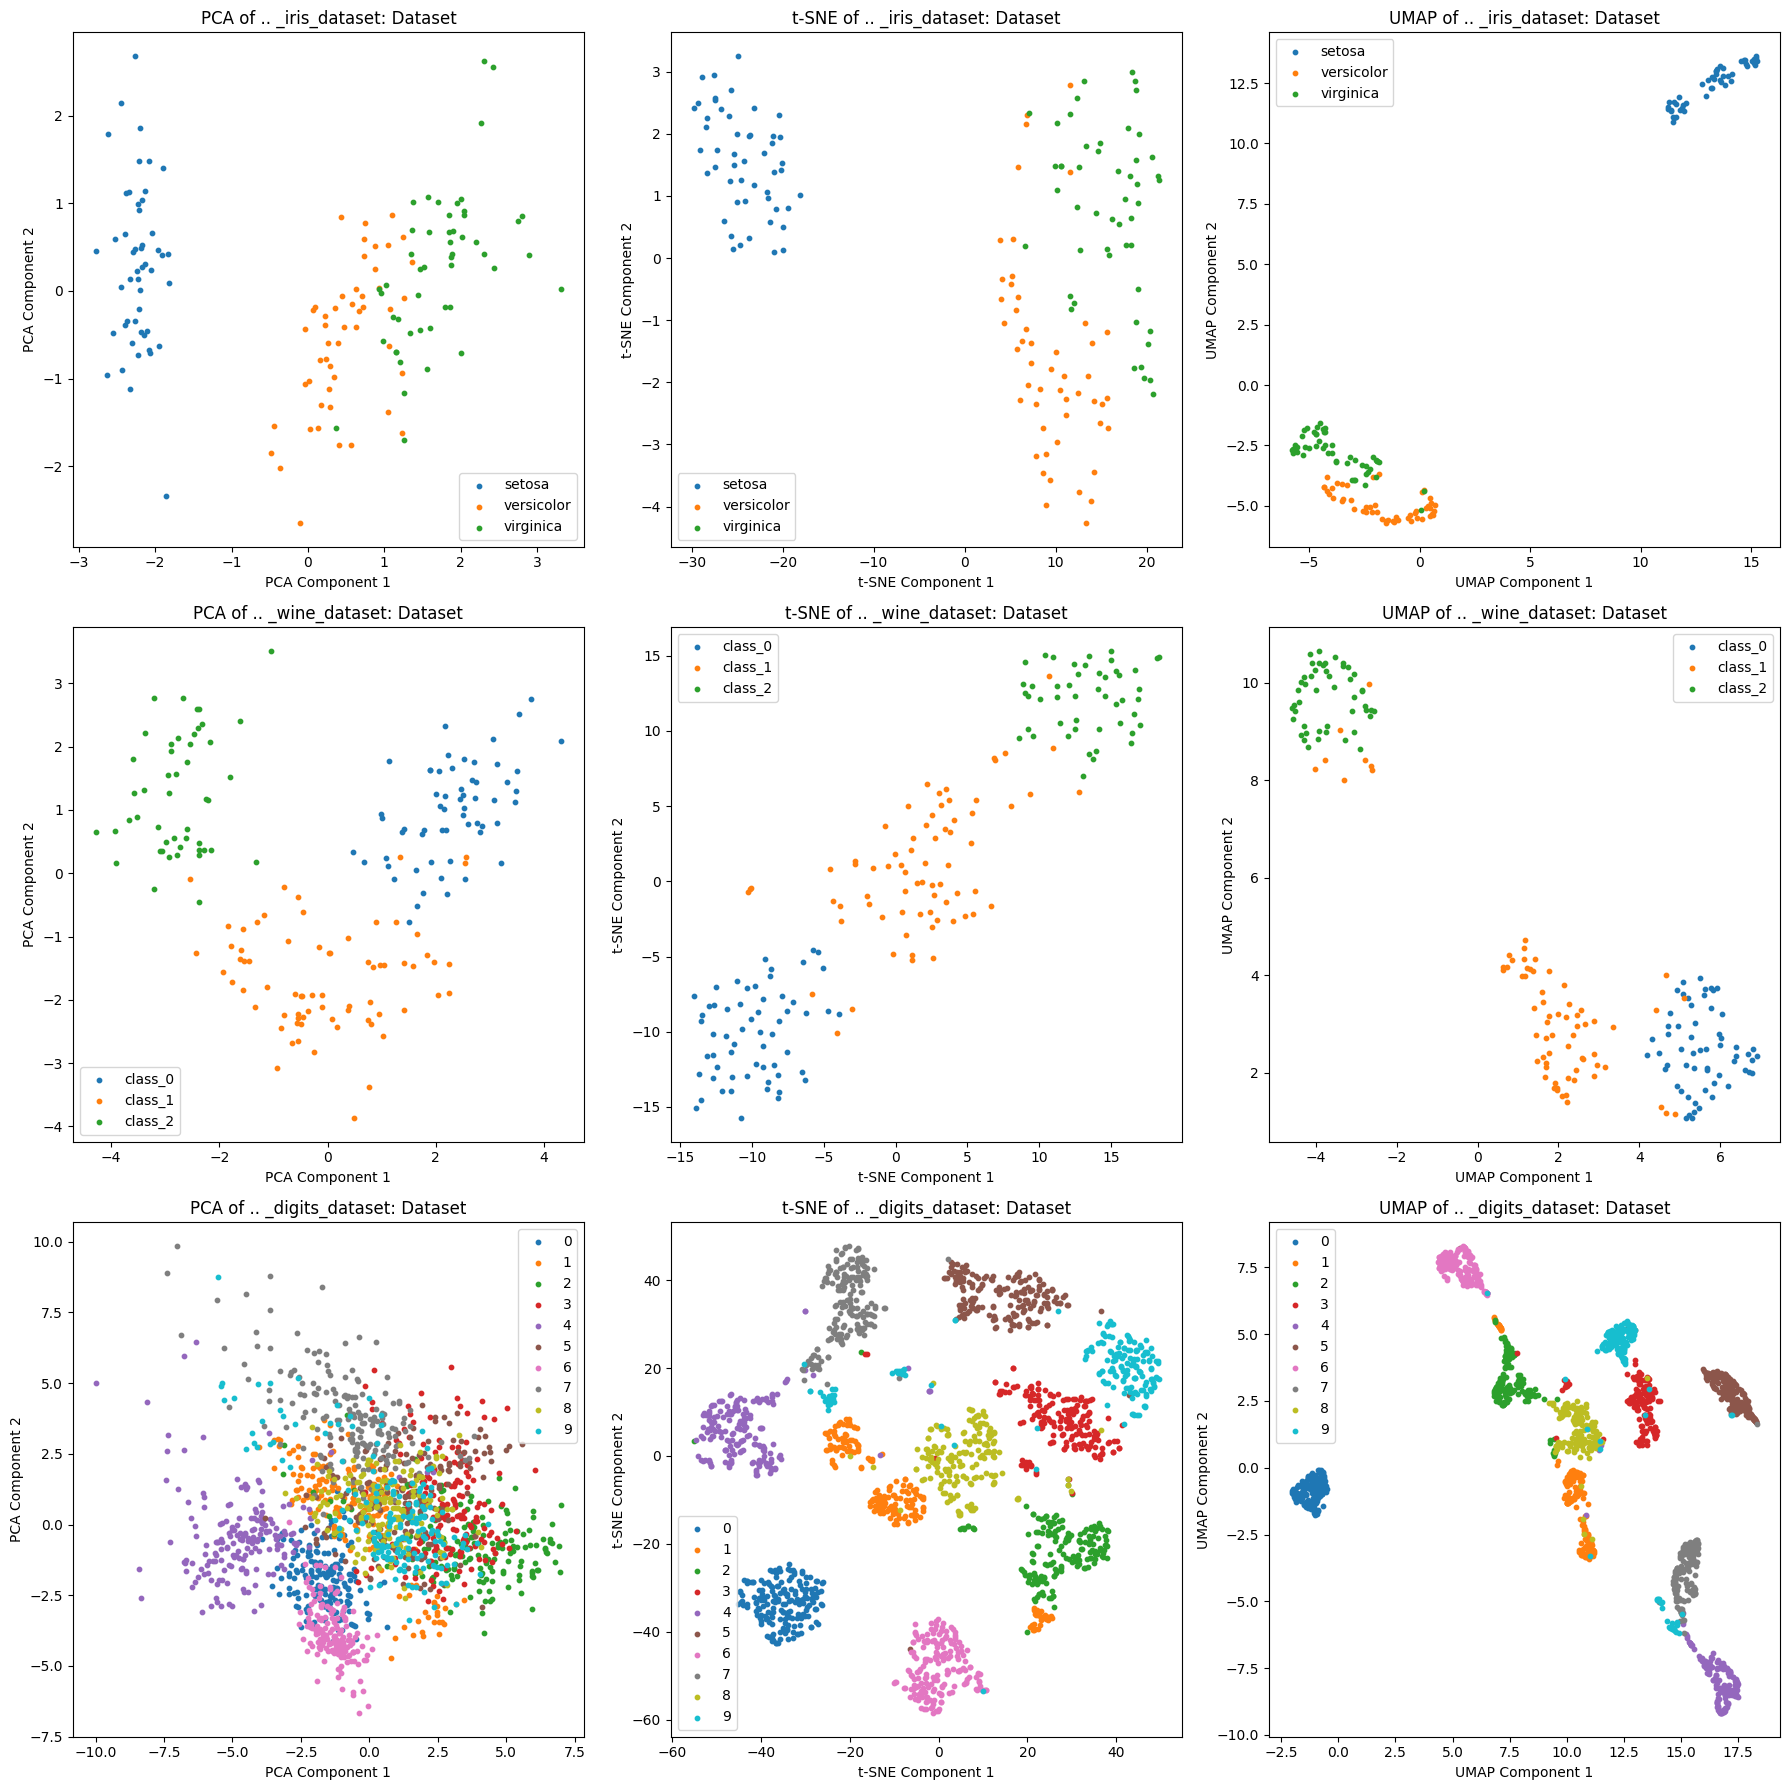

In [17]:
# Apply UMAP to the iris and wine data sets #
# Compare the results with tSNE and PCA #

# Do a 3,3 subplot grid doing PCA, tSNE and UMAP for the three datasets #
datasets = [load_iris(), load_wine(), load_digits()]
methods = ['PCA', 't-SNE', 'UMAP']
fig, axes = plt.subplots(3, 3, figsize=(18, 18))
for i, data in enumerate(datasets):
    X = data.data
    y = data.target
    # Standardize the data
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    for j, method in enumerate(methods):
        ax = axes[i, j]
        if method == 'PCA':
            reducer = PCA(n_components=2)
            X_reduced = reducer.fit_transform(X_scaled)
        elif method == 't-SNE':
            reducer = TSNE(n_components=2, perplexity=25)
            X_reduced = reducer.fit_transform(X_scaled)
        elif method == 'UMAP':
            reducer = UMAP(n_neighbors=15, min_dist=0.1, n_components=2)
            X_reduced = reducer.fit_transform(X_scaled)
        
        for k, target_name in enumerate(data.target_names):
            ax.scatter(X_reduced[y == k, 0], X_reduced[y == k, 1], label=target_name, s=10)
        ax.set_title(f'{method} of {data.DESCR.splitlines()[0]} Dataset')
        ax.set_xlabel(f'{method} Component 1')
        ax.set_ylabel(f'{method} Component 2')
        ax.legend()
plt.tight_layout()
plt.show()

## Autoenconders

At last we present a different way of performing a dimensionality reduction using autoenconders. These are machine learning tool with the following architecture:

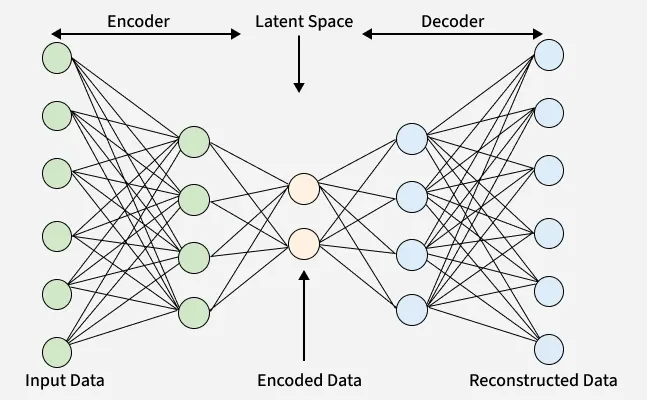

These are composed by two parts: the enconder and the decoder. The encoder will reduce the dimensionality from $d$ to $m$. Then, the decoder will increase the dimensionality from $m$ to the original dimensionality $d$. When training autoencoders to perform dimensionality reduction we want the encoder to compress as much as possible the information. On the other hand, we want the decoder to recover the original data just from the latent space information. It is for this reason that we are going to defined the loss function of this model as the Mean Square Error (MSE) when comparing the recovered data to the original one

In the notation of the lecture notes, the two NNs are

$$\text{Encoder:}\quad E_\theta: \mathbb{R}^d \rightarrow \mathbb{R}^m, \qquad \mathbf{z}_i = E_\theta(\mathbf{x}_i)$$
$$\text{Decoder:}\quad D_\phi: \mathbb{R}^m \rightarrow \mathbb{R}^d, \qquad \tilde{\mathbf{x}}_i = D_\phi(\mathbf{z}_i)$$

and they are trained together so that the reconstruction $\tilde{\mathbf{x}}_i$ is as close as possible to the original $\mathbf{x}_i$.

In the following cell we define the autoencoder model. We are using SiLU as our activation function (we need something that is very non linear). On the other hand, the output layer activation function will be a sigmoid, since we are going to normalize our data to be in between $0$ and $1$. We plot both activation functions down below.

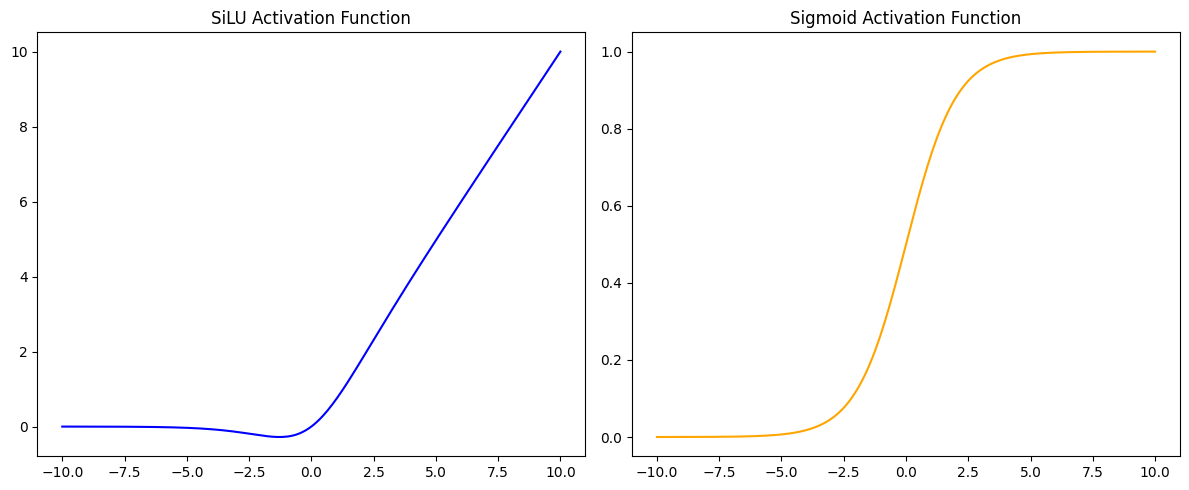

In [18]:
# Plots of the SiLU and sigmoid activation functions #
x = np.linspace(-10, 10, 200)
silu = x / (1 + np.exp(-x))
sigmoid = 1 / (1 + np.exp(-x))
fig,ax = plt.subplots(1,2,figsize=(12,5))
ax[0].plot(x, silu, color='blue')
ax[0].set_title('SiLU Activation Function')
ax[1].plot(x, sigmoid, color='orange')
ax[1].set_title('Sigmoid Activation Function')
plt.tight_layout()
plt.show()

### The data
We go back to the digits dataset. This time we simply divide the pixels by 16, so that all of them are in $[0, 1]$ like the output of the sigmoid. The labels $y_i$ are not used by the autoencoder: we only use them to color the plots and, at the end, to compare the techniques.

In [19]:
data = load_digits()
X = data.data / 16                        # data matrix, shape (n_s, d)
y = data.target                           # labels, only for plotting
print('X shape:', X.shape)

X shape: (1797, 64)


Our latent space will have $m = 3$ dimensions, so we will plot it in 3D with `plotly` (`pip install plotly`). In these plots you can **rotate** the latent space (click and drag), **zoom** (scroll), and see the coordinates of each point (hover over it). Each point is an image, colored by its digit. Clicking on a digit in the legend hides it or shows it again.

In [20]:
import plotly.express as px
import plotly.graph_objects as go

def latent_figure(Z, title='', opacity=0.7, size=2.5):
    fig = px.scatter_3d(x=Z[:, 0], y=Z[:, 1], z=Z[:, 2], color=y.astype(str), opacity=opacity, title=title,
                        color_discrete_sequence=px.colors.qualitative.D3,
                        category_orders={'color': [str(d) for d in range(10)]},
                        labels={'x': 'z1', 'y': 'z2', 'z': 'z3', 'color': 'Digit'})
    fig.update_traces(marker_size=size)
    fig.update_layout(width=700, height=550, legend_itemsizing='constant')
    return fig

def plot_embedding_3d(Z, title):
    latent_figure(Z, title).show()

To compare with the autoencoder at the end of the notebook, we also compute the embeddings of PCA, t-SNE and UMAP of this same data, with the same number of dimensions as our latent space, $m = 3$.

In [21]:
Z_pca = PCA(n_components=3).fit_transform(X)
Z_tsne = TSNE(n_components=3, perplexity=30, random_state=0).fit_transform(X)
Z_umap = UMAP(n_components=3, n_neighbors=15, min_dist=0.1, random_state=0).fit_transform(X)

### Why a convolutional layer?
A fully connected layer treats the 64 pixels as a list of numbers: if we shuffled the pixels of all the images in the same way, it would not notice. But images have **spatial structure**: neighboring pixels are related, and a stroke means the same thing wherever it appears.

A **convolutional layer** exploits this. It slides a small filter (kernel) $K$ of size $k \times k$ over the image, and computes at each position $(p, q)$

$$(K * x)_{pq} = \sum_{a, b = 1}^{k} K_{ab}\, x_{p + a,\, q + b} + b$$

The same $k^2 + 1$ weights are used everywhere in the image, so the layer has very few parameters and detects local patterns (edges, curves, ends of strokes) wherever they are. A layer uses several filters, each of them giving a new image called a **channel**.

### Several kernel sizes at the same time
The size $k$ of the kernel sets the size of the patterns that a filter can see: a $3 \times 3$ kernel sees thin, local details of a stroke, while a $7 \times 7$ kernel sees almost the whole $8 \times 8$ digit. Instead of choosing one, we apply four convolutions in parallel to the same image, with $k = 1, 3, 5, 7$, and stack their outputs as channels (this is the idea of the *Inception* networks). The rest of the network then combines small and large scale information.

The $1 \times 1$ filters are a special case: they look at a single pixel at a time, so they do not detect any pattern. Each of them multiplies every pixel by the same weight and adds a bias, so it passes a rescaled copy of the image itself to the next layer, next to the patterns found by the larger filters.

**How many filters?** A single filter detects a single pattern (for example, a vertical edge). A digit contains many different patterns: strokes in several directions, curves, corners, ends of strokes. This is why a convolutional layer always has several filters, each of them learning to detect a different pattern. We use 8 filters of each size, so the first layer gives $4 \times 8 = 32$ channels. The number of filters is a hyperparameter, like the number of neurons of a dense layer. Larger images and more complex datasets need more filters.

In [22]:
class MultiScaleConv(nn.Module):
    def __init__(self, c_in, c_out, kernels=(3, 5, 7)):
        super().__init__()
        self.branches = nn.ModuleList([nn.Conv2d(c_in, c_out, k, padding=k // 2) for k in kernels])

    def forward(self, x):
        return torch.cat([branch(x) for branch in self.branches], dim=1)   # stack the channels

### Model definition
- **Encoder.** The multi-scale block, with 8 filters of each size ($1 \times 1$, $3 \times 3$, $5 \times 5$ and $7 \times 7$): $1 \times 8 \times 8 \rightarrow 32 \times 8 \times 8$. Then we put the 32 maps in a row (`Flatten`), $32 \times 8 \times 8 = 2048$ numbers, and use fully connected layers down to the latent space: $2048 \rightarrow 256 \rightarrow 64 \rightarrow m$.
- **Decoder.** The mirror image of the fully connected part, $m \rightarrow 64 \rightarrow 256 \rightarrow 64$, whose 64 outputs are the pixels of the image (a sigmoid keeps them in $[0, 1]$). The decoder only has to produce 64 numbers out of $m = 3$, so we do not need convolutions here.

We also tried two variants: adding, after the multi-scale block, a second convolution that halves the size of the image (`stride=2`), and a decoder that goes back to 32 maps of $8 \times 8$ and combines them with a $1 \times 1$ convolution. Both gave the same results, so we keep the simplest version.

We use the SiLU activation function, as in the notes.

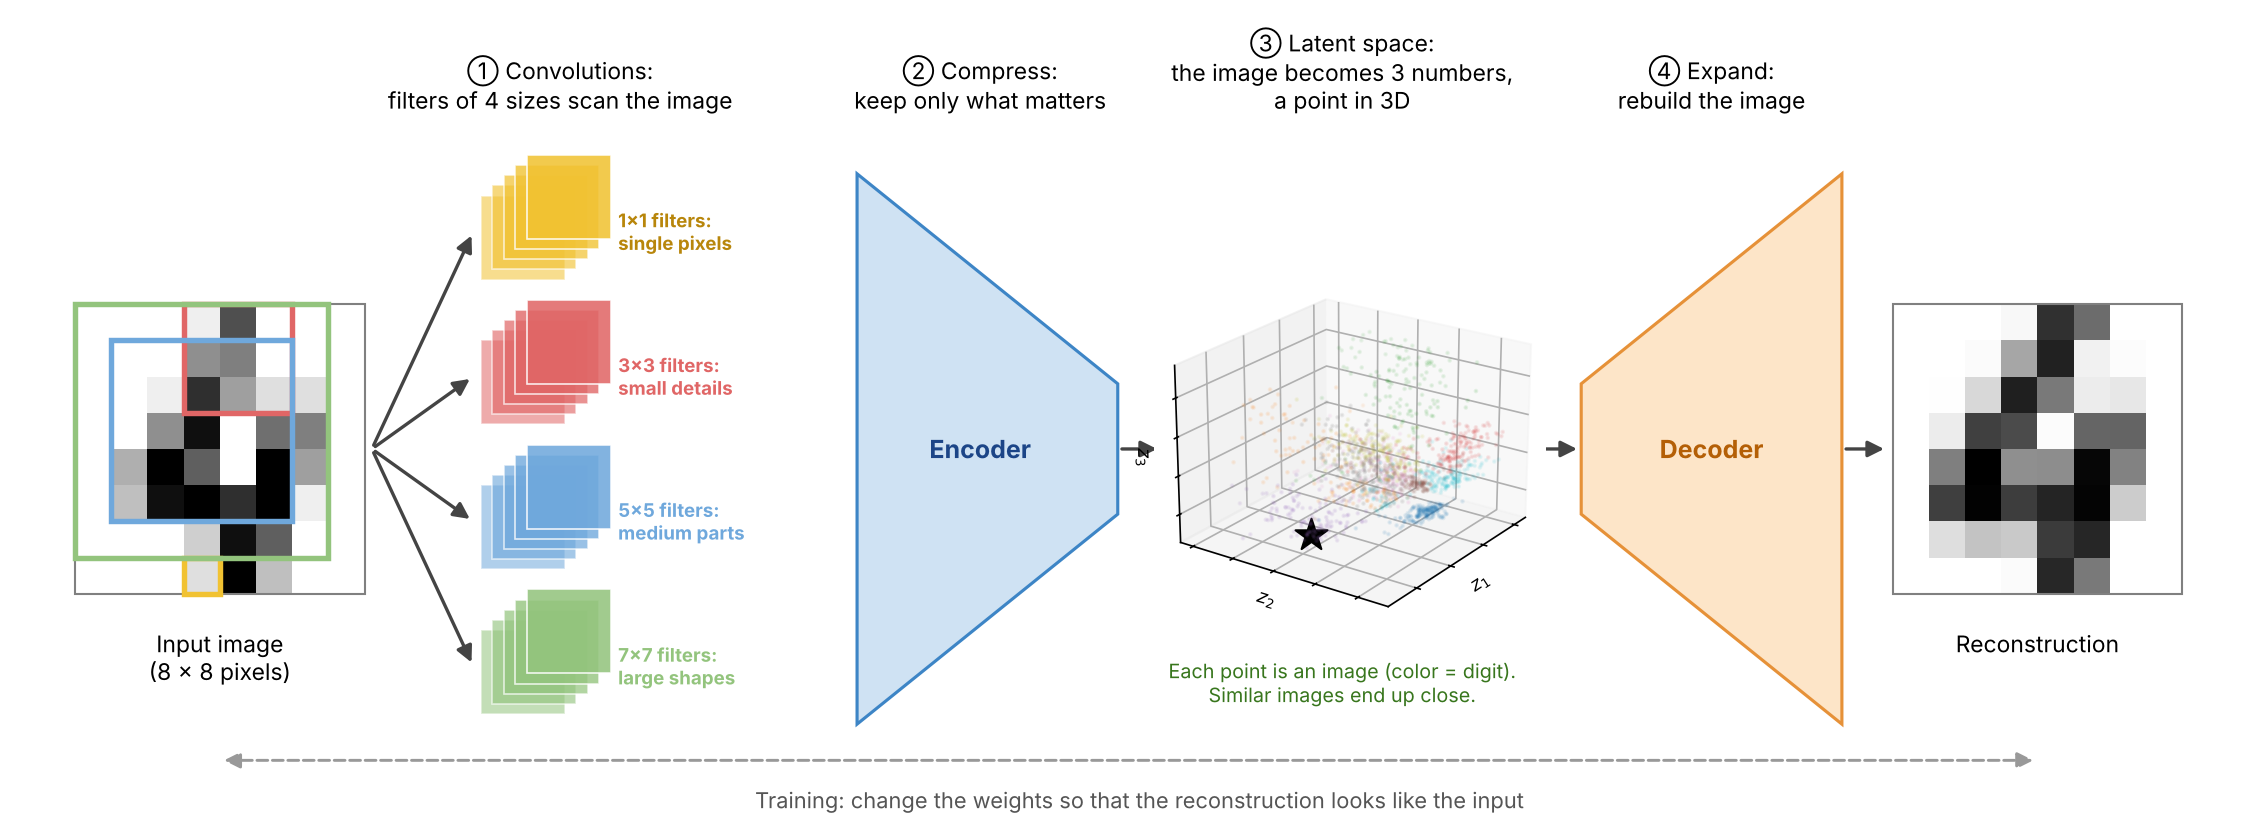

In [23]:
class CNNAutoencoder(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.encoder = nn.Sequential(
            MultiScaleConv(1, 8, kernels=(1, 3, 5, 7)), nn.SiLU(),   # 32 x 8 x 8
            nn.Flatten(),                                            # 32 maps in a row: 2048
            nn.Linear(2048, 256), nn.SiLU(),
            nn.Linear(256, 64), nn.SiLU(),
            nn.Linear(64, latent_dim))                               # z
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64), nn.SiLU(),
            nn.Linear(64, 256), nn.SiLU(),
            nn.Linear(256, 64), nn.Sigmoid(),                      # 64 pixels in [0, 1]
            nn.Unflatten(1, (1, 8, 8)))                            # 1 x 8 x 8

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z

How many numbers should the latent space have? It is a compromise. With $m = 2$ we can plot the latent space on a plane, but two numbers are too few to describe a handwritten digit, and the reconstructions are poor. With $m = 8$ or more the reconstructions are very good, but we cannot see the latent space anymore. We take $m = 3$: the reconstructions are clearly better than with $m = 2$, and we can still look at the latent space, in 3D.

In [24]:
latent_dim = 3
model = CNNAutoencoder(latent_dim)
print('Number of parameters:', sum(p.numel() for p in model.parameters()))

Number of parameters: 575235


### Training and validation sets
As explained in the overfitting section of the notes, we split the data into two disjoint sets: $70\%$ for training and $30\%$ for validation. The CNN expects images with shape `(channels, height, width)`, so we reshape each sample to $1 \times 8 \times 8$.

In [25]:
X_img = torch.tensor(X, dtype=torch.float32).reshape(-1, 1, 8, 8)
idx = torch.randperm(len(X_img))
n_train = int(0.7 * len(X_img))
X_train, X_val = X_img[idx[:n_train]], X_img[idx[n_train:]]
print('Training:', X_train.shape[0], '  Validation:', X_val.shape[0])

Training: 1257   Validation: 540


### Loss function and optimizer
The loss is the mean squared reconstruction error,

$$L(\theta, \phi) = \frac{1}{n} \sum_{i=1}^{n} \left\| \mathbf{x}_i - D_\phi\big(E_\theta(\mathbf{x}_i)\big) \right\|^2$$

evaluated on the training set for $L_\text{train}$, and on the validation set for $L_\text{val}$. Note that no labels appear: the data is its own target.

In [26]:
def ae_loss(model, x):
    x_rec, z = model(x)
    return ((x_rec - x)**2).mean()

In [27]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

### The trainer
At every epoch the trainer:

1. goes through the training set in mini-batches (as in SGD), updating the parameters $\theta$ and $\phi$ with the gradient of the loss,
2. evaluates $L_\text{train}$ and $L_\text{val}$ on the whole sets, without computing gradients,
3. keeps a copy of the model with the lowest $L_\text{val}$ (**early stopping**).

Calling `fit` again continues the training where it was left. The loss function is an argument, so that we can reuse the trainer for the VAE below.

In [28]:
class Trainer:
    def __init__(self, model, optimizer, loss, X_train, X_val, batch_size=64):
        self.model, self.optimizer, self.loss = model, optimizer, loss
        self.X_train, self.X_val, self.batch_size = X_train, X_val, batch_size
        self.history = {'train': [], 'val': []}
        self.best_loss, self.best_model = float('inf'), copy.deepcopy(model)

    def fit(self, epochs):
        bar = trange(epochs)
        for epoch in bar:
            for batch in torch.utils.data.DataLoader(self.X_train, self.batch_size, shuffle=True):
                self.optimizer.zero_grad()
                loss = self.loss(self.model, batch)
                loss.backward()
                self.optimizer.step()
            with torch.no_grad():
                L_train = self.loss(self.model, self.X_train).item()
                L_val = self.loss(self.model, self.X_val).item()
            self.history['train'].append(L_train)
            self.history['val'].append(L_val)
            if L_val < self.best_loss:
                self.best_loss, self.best_model = L_val, copy.deepcopy(self.model)
            bar.set_postfix(train=f'{L_train:.2e}', val=f'{L_val:.2e}', best=f'{self.best_loss:.2e}')

In [29]:
trainer = Trainer(model, optimizer, ae_loss, X_train, X_val)

### (Optional) Load a pretrained model

In [30]:
# trainer.best_model.load_state_dict(torch.load('results/cnn_autoencoder.pt'))

### Train the net
Choose the budget of epochs. To keep on training, just run this cell again.

In [31]:
epochs = 300

trainer.fit(epochs)

  0%|          | 0/300 [00:00<?, ?it/s]

### Visualize the results
#### Training and validation losses

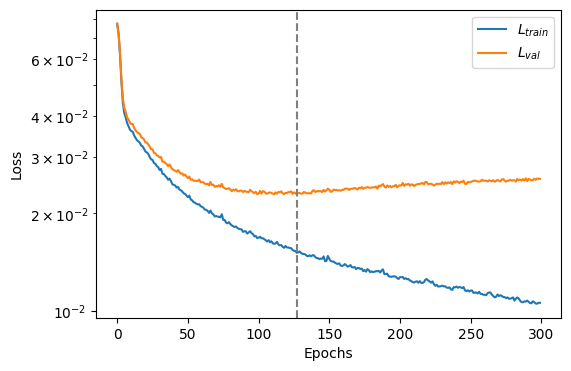

In [32]:
def plot_losses(history):
    plt.figure(figsize=(6, 4))
    plt.plot(history['train'], label='$L_{train}$')
    plt.plot(history['val'], label='$L_{val}$')
    plt.axvline(np.argmin(history['val']), color='gray', linestyle='--')
    plt.yscale('log')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()

plot_losses(trainer.history)

This is the behaviour described in the overfitting section of the notes. At the beginning both losses decrease together. After some epochs (dashed line), $L_\text{train}$ keeps decreasing but $L_\text{val}$ starts to grow: the network is memorizing the training images. From now on we use `trainer.best_model`, the model at the minimum of $L_\text{val}$.

In [33]:
model = trainer.best_model

#### Reconstructions
Original validation images (top) and their reconstructions $\tilde{\mathbf{x}} = D_\phi(E_\theta(\mathbf{x}))$ (bottom). These images were never used for training.

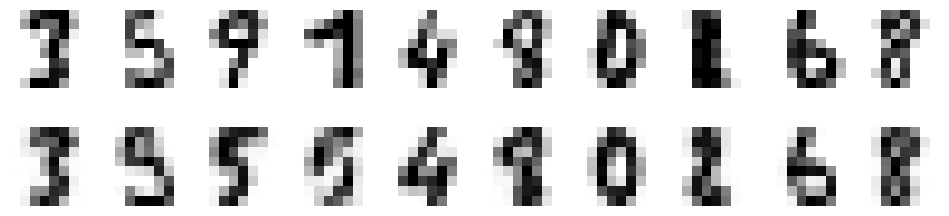

In [34]:
with torch.no_grad():
    X_rec = model(X_val[:10])[0]

fig, ax = plt.subplots(2, 10, figsize=(12, 2.8))
for i in range(10):
    ax[0, i].imshow(X_val[i, 0], cmap='gray_r')
    ax[1, i].imshow(X_rec[i, 0], cmap='gray_r')
    ax[0, i].axis('off'); ax[1, i].axis('off')
plt.show()

With only $m = 3$ numbers per image, the reconstructions are not perfect, but most digits are recognizable.

#### Latent space
We encode all the images and plot $\mathbf{z}_i = E_\theta(\mathbf{x}_i)$.

In [35]:
with torch.no_grad():
    Z_ae = model.encoder(X_img).numpy()
plot_embedding_3d(Z_ae, 'CNN autoencoder')

The digits are grouped, much better than with PCA, but the clusters are less separated than with t-SNE or UMAP. This is expected: t-SNE and UMAP are built to keep neighbors together, while the autoencoder was only asked to *reconstruct* the images from 3 numbers. The fair comparison is with PCA: as mentioned in the notes, a linear autoencoder is equivalent to PCA, so the improvement comes from the non-linearities.

What the autoencoder gives us, and t-SNE and UMAP do not, is an explicit function $E_\theta$ that we can apply to new images, and a decoder $D_\phi$ to go back from the latent space to images.

#### Walking through the latent space
Since we have the decoder, we can go in the other direction: choose any point $\mathbf{z}$ of the latent space and look at the image $D_\phi(\mathbf{z})$. We cannot draw a 3D grid of images, so we take a **slice** of the latent space: we fix $z_3$ to its median value, and decode a $10 \times 10$ grid of points of the $(z_1, z_2)$ plane, covering the region where most of the data lies (between the 2nd and 98th percentiles of each coordinate).

In [36]:
def plot_decoded_grid(decoder, z1, z2, z3):
    fig, ax = plt.subplots(len(z2), len(z1), figsize=(6, 6))
    with torch.no_grad():
        for i, b in enumerate(z2):
            for j, a in enumerate(z1):
                ax[i, j].imshow(decoder(torch.tensor([[a, b, z3]], dtype=torch.float32))[0, 0], cmap='gray_r')
                ax[i, j].axis('off')
    plt.show()

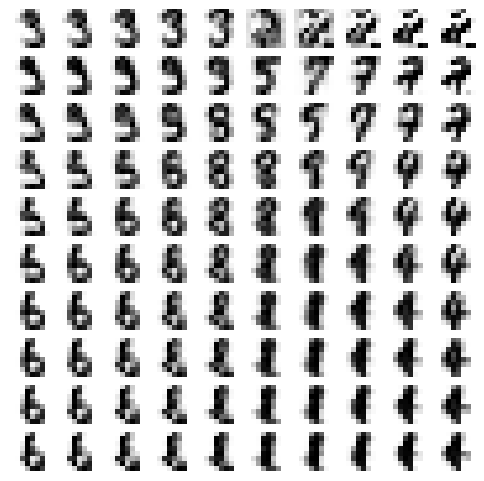

In [37]:
lo, hi = np.percentile(Z_ae, [2, 98], axis=0)
plot_decoded_grid(model.decoder, np.linspace(lo[0], hi[0], 10), np.linspace(hi[1], lo[1], 10), np.median(Z_ae[:, 2]))

The images change continuously from one digit to another, and the points between two clusters decode to a mixture of both digits. However, nothing controls what the decoder does in the regions of the latent space without data. This is the motivation for VAEs (see below).

#### Explore the latent space yourself
Move the three sliders to choose a point $\mathbf{z} = (z_1, z_2, z_3)$ of the latent space. The point is shown in black in the 3D plot, together with all the images of the dataset, and the image that the decoder produces there appears next to the sliders. You can rotate and zoom the plot while you move the point.

This needs the package `anywidget` (`pip install anywidget`), which `plotly` uses for plots that are updated live.

In [38]:
import io
import ipywidgets as widgets
from PIL import Image

def latent_explorer(Z, decoder, lo, hi):
    fig = go.FigureWidget(latent_figure(Z, opacity=0.25, size=2))
    fig.add_scatter3d(x=[0], y=[0], z=[0], mode='markers', name='Selected z',
                      marker=dict(size=9, color='black', symbol='diamond'))
    fig.update_layout(width=600, height=500, uirevision='keep')     # keep the rotation when the point moves
    sliders = [widgets.FloatSlider(value=(l + h) / 2, min=l, max=h, step=(h - l) / 100, description=f'z{j + 1}')
               for j, (l, h) in enumerate(zip(lo, hi))]
    digit = widgets.Image(format='png', width=180, height=180)

    def update(_=None):
        z = [s.value for s in sliders]
        with torch.no_grad():
            image = decoder(torch.tensor([z], dtype=torch.float32))[0, 0].numpy()
        buffer = io.BytesIO()
        Image.fromarray(np.uint8(255 * (1 - image))).resize((180, 180), Image.NEAREST).save(buffer, 'png')
        digit.value = buffer.getvalue()
        with fig.batch_update():                                        # move the black point
            fig.data[-1].x, fig.data[-1].y, fig.data[-1].z = [z[0]], [z[1]], [z[2]]

    for s in sliders:
        s.observe(update, names='value')
    update()
    return widgets.HBox([fig, widgets.VBox(sliders + [digit])])

In [39]:
lo, hi = np.percentile(Z_ae, [1, 99], axis=0)
display(latent_explorer(Z_ae, model.decoder, lo, hi))

    'data': [{'hovertemplate': 'Digit=0<br>z1=%{x}<br>z2=%{y}<br>z3=%{z}<extra><…

Try to find the points between two clusters (for example, between the 0 and the 6), where the image changes from one digit to another, and the empty regions far from the data.

### Save the model (optional)

In [40]:
os.makedirs('results', exist_ok=True)
torch.save(model.state_dict(), 'results/cnn_autoencoder.pt')

## Region sensitivity

Which regions of the image does the encoder look at to place each digit in the latent space? We measure it by **occlusion**: we cover a small $k \times k$ patch $P$ of the image (we set its pixels to 0, i.e. white), encode it again, and measure how much the latent vector moves,

$$\Delta_P(\mathbf{x}) = \left\| E_\theta(\mathbf{x}) - E_\theta(\mathbf{x}\ \text{with}\ P\ \text{covered}) \right\|$$

We slide the patch over all the positions of the image. The sensitivity $S_{pq}(\mathbf{x})$ of pixel $(p, q)$ is the average of $\Delta_P$ over all the patches that contain it. Finally, we average over all the images of each digit $d$,

$$S^{(d)}_{pq} = \frac{1}{n_d} \sum_{\mathbf{x}\, \in\, \text{digit } d} S_{pq}(\mathbf{x})$$

A large $S^{(d)}_{pq}$ means that the encoder relies on that region to recognize (and place) the digit $d$.

In [41]:
def occlusion_sensitivity(encoder, x, k=2):
    with torch.no_grad():
        z0 = encoder(x)
        S, counts = torch.zeros(len(x), 8, 8), torch.zeros(8, 8)
        for p in range(8 - k + 1):
            for q in range(8 - k + 1):
                x_occ = x.clone()
                x_occ[:, :, p:p+k, q:q+k] = 0                    # cover the patch
                shift = (encoder(x_occ) - z0).norm(dim=1)        # how much z moves
                S[:, p:p+k, q:q+k] += shift[:, None, None]
                counts[p:p+k, q:q+k] += 1
    return (S / counts).numpy()                                 # shape (n_s, 8, 8)

In [42]:
S = occlusion_sensitivity(model.encoder, X_img)
S_digit = np.array([S[y == d].mean(0) for d in range(10)])
X_mean = np.array([X[y == d].mean(0).reshape(8, 8) for d in range(10)])

Average image of each digit (top) and its sensitivity map $S^{(d)}$ (bottom, darker means more sensitive). Each map has its own color scale.

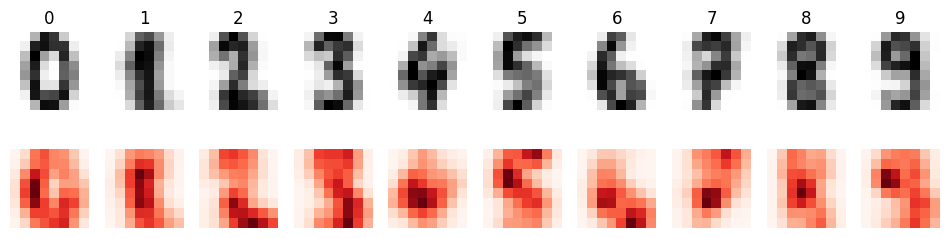

In [43]:
fig, ax = plt.subplots(2, 10, figsize=(12, 2.8))
for d in range(10):
    ax[0, d].imshow(X_mean[d], cmap='gray_r')
    ax[1, d].imshow(S_digit[d], cmap='Reds')
    ax[0, d].set_title(d)
    ax[0, d].axis('off'); ax[1, d].axis('off')
plt.show()

The sensitive regions are not simply "where the ink is": the encoder focuses on the strokes that distinguish a digit from the ones that are close to it in the latent space. For example, the crossing of the strokes of the 4, the left side of the 0, the base of the 2, the lower loop of the 6, or the middle of the diagonal of the 7.

Note that covering a patch with white can only remove ink, so the empty regions of an image (like the hole of the 0) have low sensitivity by construction.

## Variational Autoencoders (VAEs)

We have seen two problems of the latent space of the autoencoder: it has "holes" (regions without data where the decoder produces nonsense), and nothing fixes the scale or the position of the clusters, so we do not know where to look for new samples.

A **Variational Autoencoder** solves this by making the encoder probabilistic:

- The encoder gives two vectors for each image: a mean $\boldsymbol{\mu}_\theta(\mathbf{x})$ and a variance $\boldsymbol{\sigma}^2_\theta(\mathbf{x})$ (in practice, $\log \boldsymbol{\sigma}^2$, which can take any sign).
- The latent vector is sampled, $\mathbf{z} = \boldsymbol{\mu} + \boldsymbol{\sigma} \odot \boldsymbol{\epsilon}$ with $\boldsymbol{\epsilon} \sim \mathcal{N}(0, 1)$. Writing it this way (the *reparametrization trick*) keeps $\mathbf{z}$ differentiable with respect to $\theta$.
- The loss has two terms, the reconstruction error and the Kullback-Leibler divergence between $\mathcal{N}(\boldsymbol{\mu}, \boldsymbol{\sigma}^2)$ and $\mathcal{N}(0, 1)$:

$$L_\text{VAE} = \frac{1}{n}\sum_{i=1}^{n} \left[ \left\| \mathbf{x}_i - D_\phi(\mathbf{z}_i) \right\|^2 + \beta\, \frac{1}{2} \sum_{j=1}^{m} \left( \mu_{ij}^2 + \sigma_{ij}^2 - \log \sigma_{ij}^2 - 1 \right) \right]$$

The second term pulls all the images towards a standard normal distribution in the latent space, so the clusters are packed together around the origin without holes. Then any $\mathbf{z} \sim \mathcal{N}(0, 1)$ decodes to a reasonable image, and the decoder becomes a **generative model**. The weight $\beta$ balances the quality of the reconstructions against the regularity of the latent space.

### Model definition
We reuse the CNN autoencoder. The only changes are that the encoder now has $2m$ outputs ($\boldsymbol{\mu}$ and $\log \boldsymbol{\sigma}^2$), and that a random $\mathbf{z}$ is sampled before the decoder (see the figure: the image is now mapped to a cloud, and we pick a random point in it).

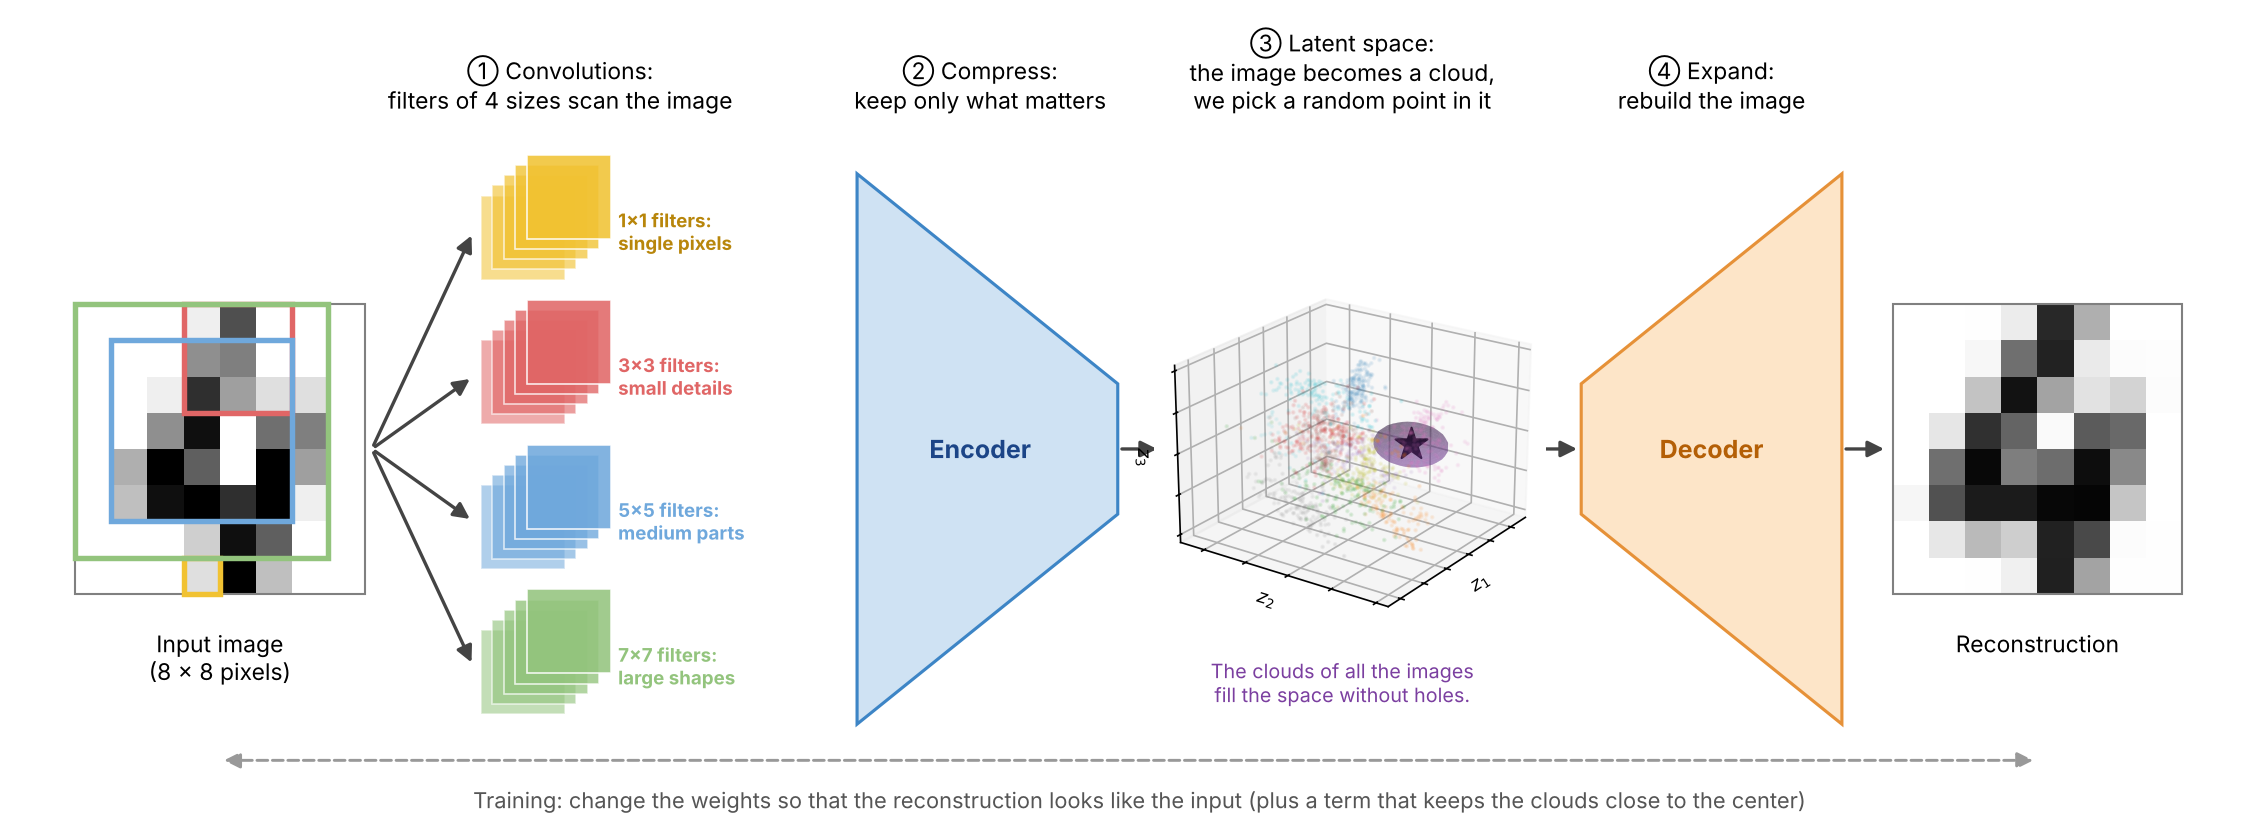

In [44]:
class CNNVAE(CNNAutoencoder):
    def __init__(self, latent_dim):
        super().__init__(2 * latent_dim)                 # encoder gives mu and log(sigma^2)
        self.decoder[0] = nn.Linear(latent_dim, 64)      # decoder takes z
        self.m = latent_dim

    def forward(self, x):
        h = self.encoder(x)
        mu, logvar = h[:, :self.m], h[:, self.m:]
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)    # reparametrization trick
        return self.decoder(z), mu, logvar

### Loss function

In [45]:
beta = 0.3

def vae_loss(model, x):
    x_rec, mu, logvar = model(x)
    reconstruction = ((x_rec - x)**2).sum(dim=(1, 2, 3)).mean()
    KL = 0.5 * (mu**2 + logvar.exp() - logvar - 1).sum(dim=1).mean()
    return reconstruction + beta * KL

### Train the net
Same trainer as before, with the new model and loss.

In [46]:
vae = CNNVAE(latent_dim)
optimizer_vae = torch.optim.Adam(vae.parameters(), lr=1e-3)
trainer_vae = Trainer(vae, optimizer_vae, vae_loss, X_train, X_val)

In [47]:
epochs = 300

trainer_vae.fit(epochs)

  0%|          | 0/300 [00:00<?, ?it/s]

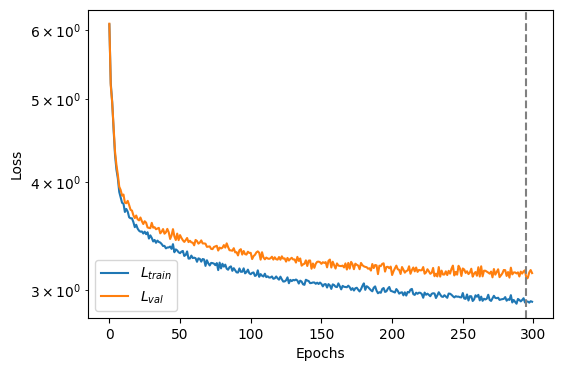

In [48]:
plot_losses(trainer_vae.history)

### Latent space
We plot the mean $\boldsymbol{\mu}_\theta(\mathbf{x}_i)$ of each image.

In [49]:
vae = trainer_vae.best_model
with torch.no_grad():
    Z_vae = vae.encoder(X_img)[:, :latent_dim].numpy()
plot_embedding_3d(Z_vae, 'CNN VAE')

Compared with the autoencoder, the clusters are now arranged around the origin, all of them at a similar scale, and there is much less empty space between them. Most digits get their own region, and a few of them overlap close to the center, where several clusters meet.

### Generating new digits
We decode a grid of points of the slice $z_3 = 0$, with $(z_1, z_2) \in [-2, 2] \times [-2, 2]$, where the KL term has placed the data. None of these images is in the dataset.

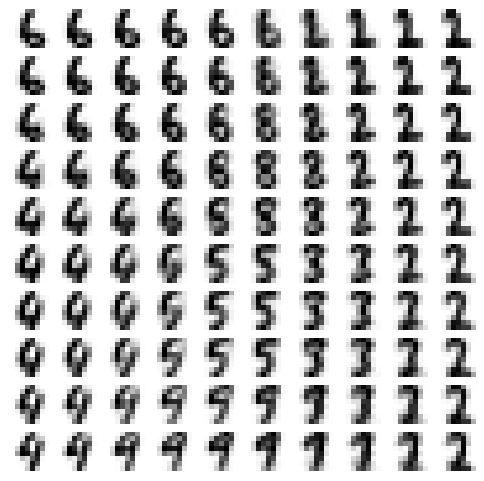

In [50]:
plot_decoded_grid(vae.decoder, np.linspace(-2, 2, 10), np.linspace(2, -2, 10), 0)

Almost every point of the grid decodes to a recognizable digit, and moving across the grid changes one digit smoothly into another. This is what makes the VAE a **generative model**: we can sample $\mathbf{z} \sim \mathcal{N}(0, 1)$, decode it, and obtain a new digit.

#### Explore the latent space of the VAE
Same as for the autoencoder: move the sliders and rotate the plot. Compare with the latent space of the autoencoder: are there still regions that give images that do not look like digits?

In [51]:
display(latent_explorer(Z_vae, vae.decoder, [-2.5, -2.5, -2.5], [2.5, 2.5, 2.5]))

    'data': [{'hovertemplate': 'Digit=0<br>z1=%{x}<br>z2=%{y}<br>z3=%{z}<extra><…

## Comparison

How well does each embedding keep similar images together? A simple measure: for each validation image, look at its 5 nearest neighbors among the training images *in the embedding* (all of them have 3 dimensions), and check whether most of them are the same digit (a $k$-nearest-neighbors classifier). The labels are used only to evaluate, never to build the embeddings.

In [52]:
train_idx, val_idx = idx[:n_train].numpy(), idx[n_train:].numpy()
for name, Z in [('PCA', Z_pca), ('t-SNE', Z_tsne), ('UMAP', Z_umap), ('Autoencoder', Z_ae), ('VAE', Z_vae)]:
    knn = KNeighborsClassifier(n_neighbors=5).fit(Z[train_idx], y[train_idx])
    print(f'{name:12s} {100 * knn.score(Z[val_idx], y[val_idx]):.0f}%')

PCA          74%
t-SNE        99%
UMAP         99%
Autoencoder  89%
VAE          90%


PCA keeps similar images together for only about 60% of the images. The autoencoder and the VAE do much better, and t-SNE and UMAP are almost perfect (the exact numbers change a bit from run to run).

So, if the only goal is a 2D or 3D plot of the data, t-SNE or UMAP are the best tools: they are built precisely to keep neighbors together. The (variational) autoencoders are useful for other things: they give a function $E_\theta$ that encodes new data, a decoder $D_\phi$ that reconstructs it, and, in the case of the VAE, a way to generate new samples. With a larger latent space ($m > 3$) they are also an efficient way of compressing the data.

## Draw your own digit

Finally, let us use the trained models on a digit drawn by you. You can choose the VAE (default) or the autoencoder. For the VAE, the position of the image in the latent space is the mean $\boldsymbol{\mu}$ of its cloud, and we also draw its cloud, an ellipsoid with semi-axes $\sigma_1, \sigma_2, \sigma_3$.

For a given image, the function `analyze`:

1. computes the occlusion sensitivity of the *Region sensitivity* section, to see which regions of *your* drawing the encoder is looking at,
2. reconstructs the drawing, $D_\phi(E_\theta(\mathbf{x}))$,
3. places it in the latent space, on top of the dataset (in a 3D plot that you can rotate), and tells which digit its closest neighbors are,
4. shows the output of the four branches of the multi-scale convolution. Note that these are **not** the filters themselves: each filter slides over the whole image, so its output is again an $8 \times 8$ image, with one value $(K * x)_{pq}$ for each position $(p, q)$ of the filter. We plot $|(K * x)_{pq}|$ averaged over the 8 filters of each branch, so a bright pixel means that the $k \times k$ filters centered there respond strongly. The $1 \times 1$ filters only see one pixel, so their output looks like the image itself. The $3 \times 3$ filters respond along the strokes, while the large ones see a whole region around each pixel and give smoother maps.

The **predicted digit** is the most common digit among the 5 images of the dataset that are closest to your drawing in the latent space. Note that this uses the labels, which the (variational) autoencoder never saw during training: the prediction only tells us which digits are around your drawing in the latent space.

In [53]:
models = {'VAE': (vae, Z_vae), 'Autoencoder': (model, Z_ae)}
knn_latent = {name: KNeighborsClassifier(n_neighbors=5).fit(Z, y) for name, (net, Z) in models.items()}

def predict(image, name):
    x = torch.tensor(image, dtype=torch.float32).reshape(1, 1, 8, 8)
    with torch.no_grad():
        z = models[name][0].encoder(x)[:, :latent_dim]        # for the VAE, the mean mu
    return knn_latent[name].predict(z.numpy())[0]

In [54]:
def analyze(image, name='VAE'):
    net, Z = models[name]
    encode = lambda x: net.encoder(x)[:, :latent_dim]           # z for the autoencoder, mu for the VAE
    x = torch.tensor(image, dtype=torch.float32).reshape(1, 1, 8, 8)
    S = occlusion_sensitivity(encode, x)[0]
    with torch.no_grad():
        z = encode(x)
        x_rec = net.decoder(z)
        branches = [b(x)[0].abs().mean(0) for b in net.encoder[0].branches]
        sizes = [b.kernel_size[0] for b in net.encoder[0].branches]          # kernel size of each branch
        sigma = torch.exp(0.5 * net.encoder(x)[0, latent_dim:]).numpy() if name == 'VAE' else None
    z = z[0].numpy()
    digit = knn_latent[name].predict([z])[0]

    fig, ax = plt.subplots(2, max(3, len(sizes)), figsize=(3.3 * max(3, len(sizes)), 6.5))
    ax[0, 0].imshow(image, cmap='gray_r'); ax[0, 0].set_title('Your digit')
    ax[0, 1].imshow(image, cmap='gray_r'); ax[0, 1].imshow(S, cmap='Reds', alpha=0.6); ax[0, 1].set_title('Where the encoder looks')
    ax[0, 2].imshow(x_rec[0, 0], cmap='gray_r'); ax[0, 2].set_title('Reconstruction')
    for k, (b, size) in enumerate(zip(branches, sizes)):
        ax[1, k].imshow(b, cmap='viridis'); ax[1, k].set_title(f'Output of the {size}x{size} filters')
    for a in ax.flat:
        a.set_xticks([]); a.set_yticks([])
    for a in ax[0, 3:]:                                          # empty panels of the first row
        a.axis('off')
    plt.show()

    fig = latent_figure(Z, f'{name} latent space: your digit (black) is closest to a {digit}', opacity=0.3, size=2)
    fig.add_scatter3d(x=[z[0]], y=[z[1]], z=[z[2]], mode='markers', name='Your digit',
                      marker=dict(size=8, color='black', symbol='diamond'))
    if sigma is not None:                                       # the cloud of the VAE: an ellipsoid with semi-axes sigma
        u, v = np.meshgrid(np.linspace(0, 2 * np.pi, 20), np.linspace(0, np.pi, 10))
        e = [z[j] + sigma[j] * f for j, f in enumerate([np.cos(u) * np.sin(v), np.sin(u) * np.sin(v), np.cos(v)])]
        fig.add_surface(x=e[0], y=e[1], z=e[2], opacity=0.3, showscale=False, colorscale=[[0, 'black'], [1, 'black']])
    fig.show()

Let us try it first with an image of the validation set:

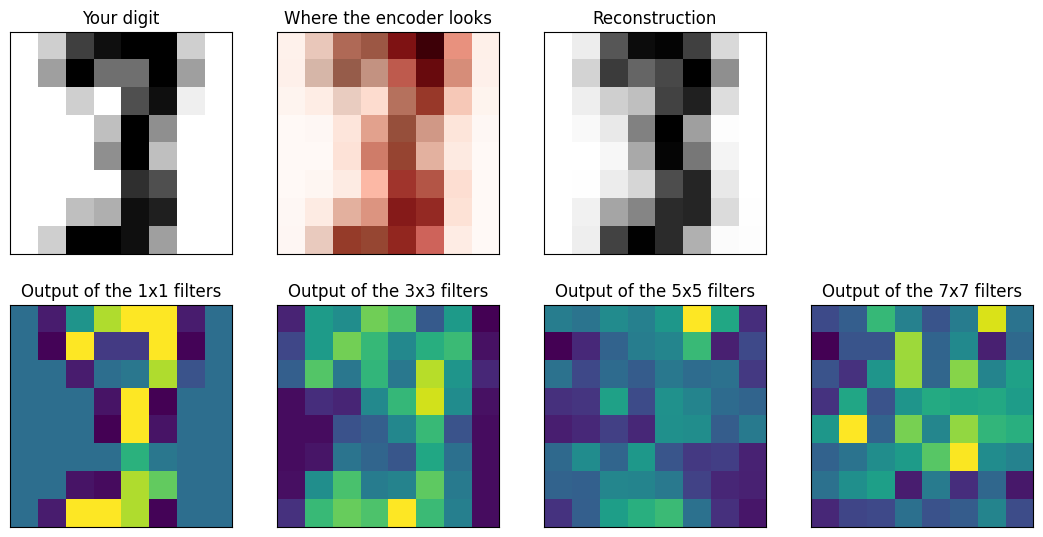

In [55]:
analyze(X_val[0, 0].numpy(), 'VAE')

### The drawing pad
Run the next three cells, draw a digit on the white square with the mouse (click and drag), and press **Analyze**: you will see how your drawing is converted into $8 \times 8$ pixels, and then the analysis. Press **Clear** to start again. The predicted digit next to the pad is updated every time you lift the pen, and when you change the model.

This needs the package `ipycanvas` (`pip install ipycanvas`). It works in JupyterLab, Jupyter Notebook and VS Code. In Google Colab, first run `from google.colab import output; output.enable_custom_widget_manager()`.

In [56]:
import ipywidgets as widgets
from ipycanvas import Canvas

size, brush = 256, 22                         # size of the canvas and width of the brush, in screen pixels
canvas = Canvas(width=size, height=size, layout=widgets.Layout(border='1px solid gray'))
canvas.line_width, canvas.line_cap, canvas.stroke_style = brush, 'round', 'black'
strokes = []                                  # each stroke is a list of points (x, y)
pen_down = False

def on_down(x, y):
    global pen_down
    pen_down = True
    strokes.append([(x, y)])

def on_move(x, y):
    if pen_down:
        canvas.stroke_line(*strokes[-1][-1], x, y)
        strokes[-1].append((x, y))

def on_up(x, y):
    global pen_down
    pen_down = False

def clear_canvas(_=None):
    strokes.clear()
    canvas.fill_style = 'white'
    canvas.fill_rect(0, 0, size, size)

canvas.on_mouse_down(on_down)
canvas.on_mouse_move(on_move)
canvas.on_mouse_up(on_up)
canvas.on_mouse_out(on_up)
clear_canvas()

#### From your drawing to 8 × 8 pixels
How do we turn a drawing into an image like the ones of the dataset? The digits of the dataset were scanned as black and white images of $32 \times 32$ pixels. Then each image was divided into blocks of $4 \times 4$ pixels, and each pixel of the final $8 \times 8$ image counts how many of the 16 small pixels of its block are black. This is why the pixels of the dataset take values between 0 and 16 (and why we divided them by 16).

We do exactly the same with your drawing:

1. **Crop** it to the region where you have drawn.
2. **Scale** it, keeping its proportions, so that its longest side is 32 pixels, and center it in a $32 \times 32$ box.
3. **Average** each block of $4 \times 4$ pixels. The result is an $8 \times 8$ image with values in $[0, 1]$: the fraction of each block covered by ink.

In [57]:
from PIL import Image, ImageDraw

def drawing_to_32(strokes):
    img = Image.new('L', (size, size), 0)                       # 0 = no ink, 255 = ink
    draw = ImageDraw.Draw(img)
    for stroke in strokes:
        draw.line(stroke, fill=255, width=brush, joint='curve')
        for x, y in stroke:                                     # round ends of the strokes
            draw.ellipse([x - brush / 2, y - brush / 2, x + brush / 2, y + brush / 2], fill=255)
    full = np.array(img) / 255
    if img.getbbox() is None:                                   # empty drawing
        return full, np.zeros((32, 32))
    img = img.crop(img.getbbox())                               # 1. crop
    scale = 32 / max(img.size)                                  # 2. scale to 32 x 32
    img = img.resize((max(1, round(img.width * scale)), max(1, round(img.height * scale))))
    box = Image.new('L', (32, 32), 0)
    box.paste(img, ((32 - img.width) // 2, (32 - img.height) // 2))
    return full, np.array(box) / 255

def drawing_to_digit(strokes):
    full, box = drawing_to_32(strokes)
    return box.reshape(8, 4, 8, 4).mean(axis=(1, 3))           # 3. average each 4 x 4 block

The following function shows the three steps. We try it with an example drawing of a 2 (each stroke is a list of points of the canvas).

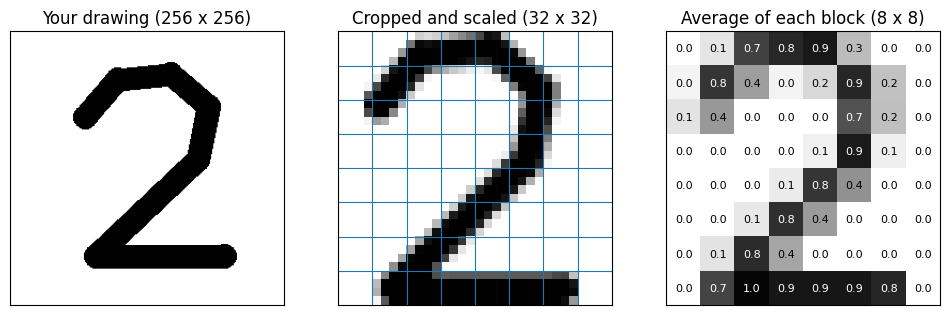

In [58]:
def plot_conversion(strokes):
    full, box = drawing_to_32(strokes)
    digit = drawing_to_digit(strokes)
    fig, ax = plt.subplots(1, 3, figsize=(12, 4))
    ax[0].imshow(full, cmap='gray_r'); ax[0].set_title(f'Your drawing ({size} x {size})')
    ax[1].imshow(box, cmap='gray_r'); ax[1].set_title('Cropped and scaled (32 x 32)')
    for k in range(1, 8):                                       # the 4 x 4 blocks
        ax[1].axhline(4 * k - 0.5, color='C0', lw=0.8); ax[1].axvline(4 * k - 0.5, color='C0', lw=0.8)
    ax[2].imshow(digit, cmap='gray_r', vmin=0, vmax=1); ax[2].set_title('Average of each block (8 x 8)')
    for (p, q), value in np.ndenumerate(digit):                 # value of each pixel
        ax[2].text(q, p, f'{value:.1f}', ha='center', va='center', fontsize=8, color='white' if value > 0.5 else 'black')
    for a in ax:
        a.set_xticks([]); a.set_yticks([])
    plt.show()

example = [[(70, 80), (100, 45), (150, 40), (185, 70), (175, 120), (80, 210), (200, 210)]]
plot_conversion(example)

In [ ]:
model_choice = widgets.ToggleButtons(options=['VAE', 'Autoencoder'], description='Model:')
prediction = widgets.HTML()
analyze_button, clear_button, output = widgets.Button(description='Analyze'), widgets.Button(description='Clear'), widgets.Output()

def show_prediction(*_):
    if strokes:
        digit = predict(drawing_to_digit(strokes), model_choice.value)
        prediction.value = ("<p style='font-size:16px; margin:0'>Predicted digit</p>"
                            f"<p style='font-size:72px; font-weight:bold; margin:0; text-align:center'>{digit}</p>")
    else:
        prediction.value = "<p style='font-size:16px'>Draw a digit</p>"

def on_analyze(_):
    show_prediction()
    with output:
        output.clear_output(wait=True)
        plot_conversion(strokes)
        analyze(drawing_to_digit(strokes), model_choice.value)

def on_clear(_):
    clear_canvas()
    output.clear_output()
    show_prediction()

canvas.on_mouse_up(show_prediction)                       # new prediction every time the pen is lifted
model_choice.observe(show_prediction, names='value')      # and when the model is changed
analyze_button.on_click(on_analyze)
clear_button.on_click(on_clear)
show_prediction()
display(widgets.HBox([canvas, widgets.VBox([model_choice, prediction, analyze_button, clear_button])]), output)

Output()

Things to look at: draw a digit very thin or very thick, or an ambiguous one (between a 4 and a 9, or between a 3 and an 8). Where does it land in the latent space, and which regions does the encoder look at? Do the VAE and the autoencoder give the same prediction?

## Things to try

- Change `latent_dim` to 2 or to 8 and compare the reconstructions and the validation loss. (The 3D plots, the grids and the explorers of this notebook assume $m = 3$: with other values you will have to adapt them. With $m = 8$, you can plot the latent vectors `Z_ae` with t-SNE or UMAP.)
- Remove the convolutional layers and use only fully connected ones. Compare the number of parameters and the best validation loss.
- Train with only 10% of the data for training. When does the validation loss start to grow?
- Change the size `k` of the patch in the occlusion. Or compute the sensitivity with derivatives instead, $\| \partial \mathbf{z} / \partial x_{pq} \|$, using `torch.autograd.grad` as in the PINNs. Which one gives clearer maps?
- Change $\beta$ in the VAE (e.g. 0.05 and 2). How do the latent space and the generated digits change?
- Compute the occlusion sensitivity of the VAE encoder and compare it with the one of the autoencoder.

# AI disclaimer 

This notebook has been prepared with the help of chatGPT, Claude and copilot.